## tentativa de previsão mais alto Etanol 2026

In [1]:
import os
import io
import certifi
import time
import optuna
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações Globais (Ignorar warnings e GUI)
warnings.filterwarnings("ignore")
plt.switch_backend('Agg')
optuna.logging.set_verbosity(optuna.logging.WARNING)

from typing import Dict, Union, List
from PIL import Image as PILImage
from matplotlib.figure import Figure
from openpyxl import Workbook
from openpyxl.worksheet.worksheet import Worksheet
from openpyxl.drawing.image import Image as OpenPyxlImage
from openpyxl.utils.dataframe import dataframe_to_rows
from openpyxl.utils import get_column_letter
from openpyxl.styles import PatternFill, Font, Alignment
from darts.timeseries import TimeSeries
from darts.models import Prophet
from darts.metrics import mape
from sklearn.metrics import mean_absolute_percentage_error
import timesfm

# Criação/Verificação das pastas do projeto
PATH_DATA = "data"
PATH_PLOTS = "plots"
PATH_CSVS = "csvs"

TIMESFM_LOCAL_PATH = "../TimesFM_pesos"
TIMESFM_CKPT_FILE = "torch_model.ckpt"

ckpt_local = os.path.join(TIMESFM_LOCAL_PATH, TIMESFM_CKPT_FILE)

print("PWD:", os.getcwd())
print("TimesFM existe?", os.path.exists("../TimesFM_pesos"))
print("Checkpoint existe?", os.path.exists("TimesFM/torch_model.ckpt"))

os.makedirs(PATH_PLOTS, exist_ok=True)
os.makedirs(PATH_CSVS, exist_ok=True)

if not os.path.exists(PATH_DATA):
    print(f"Erro: A pasta '{PATH_DATA}' não foi encontrada no diretório atual.")
    print(f"Por favor, crie a pasta '{PATH_DATA}' e coloque o arquivo Excel dentro dela.")
    exit(1)





PWD: /srv/shared/CicloOtto/auto_otto_ge/auto_ge
TimesFM existe? True
Checkpoint existe? False


In [3]:
# Estrutura auxiliar para Excel

class ExcelBuilder:
    def __init__(self, output_path: str) -> None:
        self.output_path = output_path
        self.workbook = Workbook()
        self.sheets: Dict[str, Worksheet] = {}
        self.current_row: Dict[str, int] = {}
        if "Sheet" in self.workbook.sheetnames:
            self.workbook.remove(self.workbook["Sheet"])

    def create_sheet(self, sheet_name: str) -> "ExcelBuilder":
        if sheet_name not in self.workbook.sheetnames:
            self.sheets[sheet_name] = self.workbook.create_sheet(sheet_name)
            self.current_row[sheet_name] = 1
        return self

    def create_sheets(self, sheet_names: List[str]) -> "ExcelBuilder":
        for sheet_name in sheet_names:
            self.create_sheet(sheet_name)
        return self

    def _write_header(self, ws, title, num_cols, start_col, current_row,
                      title_fill_color="808080", columns_fill_color="B0B0B0") -> int:
        ws.cell(row=current_row, column=start_col + 1, value=title).fill = PatternFill(
            patternType="solid", fgColor=title_fill_color
        )
        ws.cell(row=current_row, column=start_col + 1).font = Font(bold=True, color="FFFFFF", size=12)
        ws.cell(row=current_row, column=start_col + 1).alignment = Alignment(horizontal="center", vertical="center")

        ws.merge_cells(
            f"{get_column_letter(start_col + 1)}{current_row}:{get_column_letter(start_col + num_cols)}{current_row}"
        )
        ws.row_dimensions[current_row].height = 20

        for c_idx in range(start_col + 1, start_col + num_cols + 1):
            cell = ws.cell(row=current_row + 1, column=c_idx)
            cell.fill = PatternFill(patternType="solid", fgColor=columns_fill_color)
            cell.font = Font(bold=True, color="FFFFFF")
            cell.alignment = Alignment(horizontal="center")

        return current_row + 1

    def add_dataframe_figure_pair(self, sheet_name, dataframe, figure, title="",
                                  start_col=0, image_col_offset=6, row_gap=15,
                                  title_fill_color="808080", columns_fill_color="B0B0B0") -> "ExcelBuilder":
        if sheet_name not in self.sheets:
            raise ValueError(f"A aba '{sheet_name}' não existe.")

        ws = self.sheets[sheet_name]
        current_row = self.current_row[sheet_name]

        if title:
            data_start_row = self._write_header(
                ws, title, len(dataframe.columns), start_col, current_row,
                title_fill_color, columns_fill_color
            ) + 1

            for c_idx, col_name in enumerate(dataframe.columns, start=start_col + 1):
                ws.cell(row=data_start_row - 1, column=c_idx, value=col_name)

            for r_idx, row in enumerate(dataframe_to_rows(dataframe, index=False, header=False), start=data_start_row):
                for c_idx, value in enumerate(row, start=start_col + 1):
                    ws.cell(row=r_idx, column=c_idx, value=value)
        else:
            for r_idx, row in enumerate(dataframe_to_rows(dataframe, index=False, header=True), start=current_row):
                for c_idx, value in enumerate(row, start=start_col + 1):
                    ws.cell(row=r_idx, column=c_idx, value=value)

        self._adjust_column_widths(ws, dataframe, start_col, title)

        if isinstance(figure, str):
            figure = PILImage.open(figure)
        if not isinstance(figure, PILImage.Image):
            buf = io.BytesIO()
            figure.savefig(buf, format="png", bbox_inches="tight")
            buf.seek(0)
            figure = PILImage.open(buf)

        image_buf = io.BytesIO()
        figure.save(image_buf, format="PNG")
        image_buf.seek(0)
        img = OpenPyxlImage(image_buf)

        ws.add_image(img, f"{get_column_letter(start_col + image_col_offset + 1)}{current_row}")
        self.current_row[sheet_name] = current_row + ((2 if title else 0) + len(dataframe)) + row_gap + 1
        return self

    def _adjust_column_widths(self, worksheet, dataframe, start_col, title="") -> None:
        num_cols = len(dataframe.columns)
        for col_idx, column in enumerate(dataframe.columns, start=start_col):
            col_letter = get_column_letter(col_idx + 1)
            max_length = max(len(str(column)), *(len(str(x)) for x in dataframe[column]))
            if title:
                max_length = max(max_length, (len(title) // num_cols) + 2)
            worksheet.column_dimensions[col_letter].width = max_length + 2

    def save(self) -> None:
        self.workbook.save(self.output_path)

    def close(self) -> None:
        if hasattr(self, "workbook"):
            self.workbook.close()

In [5]:
##############################################################################################
# Leitura

controle = os.path.join(PATH_DATA, "arquivos_processados.txt")

while True:
    # Arquivos já processados
    if os.path.exists(controle):
        with open(controle, "r", encoding="utf-8") as f:
            arquivos_processados = set(
                linha.strip() for linha in f if linha.strip()
            )
    else:
        arquivos_processados = set()

    # Arquivos existentes na pasta
    arquivos_data = {
        arq for arq in os.listdir(PATH_DATA)
        if arq.endswith((".xlsx", ".xls"))
    }

    # Apenas arquivos novos
    novos_arquivos = arquivos_data - arquivos_processados

    if not novos_arquivos:
        print("Nenhum arquivo novo adicionado")
        time.sleep(1)
        continue

    for arquivo in sorted(novos_arquivos):

        excel_file = os.path.join(PATH_DATA, arquivo)

        print(f" -> Lendo dados de: {excel_file}")

        df = pd.read_excel(excel_file)

        with open(controle, "a", encoding="utf-8") as f:
            f.write(f"{arquivo}\n")
            print("finalizada a leitura")



 -> Lendo dados de: data/Dados Demanda Ciclo Otto 3107 - 1.xlsx
finalizada a leitura
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado


KeyboardInterrupt: 

In [7]:
   ##############################################################################################
    #  preparação dos dados


df = (
    pd.read_excel(excel_file, sheet_name="Demanda Ciclo Otto (ANP)")
      .rename(columns={
          "Unnamed: 0": "Data",
          "Demanda Etanol Hidratado (m3)": "Etanol",
          "Demanda Gasolina C (m3)": "Gasolina",
          "Demanda Ciclo Otto (m3 gasolina equivalente)": "Otto"
      })
)
df["Data"] = pd.to_datetime(df["Data"])

otto_series = TimeSeries.from_dataframe(df, time_col="Data", value_cols="Otto", freq="MS")
gasolina_series = TimeSeries.from_dataframe(df, time_col="Data", value_cols="Gasolina", freq="MS")
etanol_series = TimeSeries.from_dataframe(df, time_col="Data", value_cols="Etanol", freq="MS")

series_dict = {
    "Otto": otto_series,
    "Gasolina": gasolina_series,
    "Etanol": etanol_series,
}

In [9]:
# Verifica o que existe no notebook
print("Variáveis disponíveis:")
for name in sorted(globals().keys()):
    if 'train' in name.lower() or 'val' in name.lower() or 'df' in name.lower():
        obj = globals()[name]
        tipo = type(obj).__name__
        if hasattr(obj, 'shape'):
            print(f"  {name}: {tipo} {obj.shape}")
        elif hasattr(obj, '__len__'):
            print(f"  {name}: {tipo} (len={len(obj)})")
        else:
            print(f"  {name}: {tipo}")

Variáveis disponíveis:
  df: DataFrame (197, 4)


In [17]:
df['Etanol']

from darts import TimeSeries

# 1. Cria TimeSeries
serie = TimeSeries.from_dataframe(
    df,
    time_col="Data",
    value_cols="Etanol"
)

# 2. Divide
train, val = serie.split_before(0.8)

# 3. Volta para pandas para usar Prophet
train_copy = train.pd_dataframe().reset_index()

# 4. Prophet precisa de ds e y
train_copy.columns = ["ds", "y"]
# 5. Floor
train_copy["floor"] = 0.0




In [19]:
# Verifica o que existe no notebook
print("Variáveis disponíveis:")
for name in sorted(globals().keys()):
    if 'train' in name.lower() or 'val' in name.lower() or 'df' in name.lower():
        obj = globals()[name]
        tipo = type(obj).__name__
        if hasattr(obj, 'shape'):
            print(f"  {name}: {tipo} {obj.shape}")
        elif hasattr(obj, '__len__'):
            print(f"  {name}: {tipo} (len={len(obj)})")
        else:
            print(f"  {name}: {tipo}")

Variáveis disponíveis:
  df: DataFrame (197, 4)
  train: TimeSeries (len=156)
  train_copy: TimeSeries (len=156)
  val: TimeSeries (len=41)


In [22]:
import pandas as pd
import numpy as np
from prophet import Prophet
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# ── CONVERTE TimeSeries → DataFrame (formato Prophet) ──
def ts_to_prophet(ts):
    df = ts.pd_dataframe()
    df = df.reset_index()
    df.columns = ["ds", "y"]
    return df

train_df = ts_to_prophet(train)
val_df = ts_to_prophet(val)

# ── GRID MANUAL ──
results = []

for cps in [0.20, 0.30, 0.50, 0.80, 1.0, 2.0, 5.0]:
    for cr in [0.95, 0.98, 0.99]:
        # ... mesmo código

#for cps in [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.10, 0.12, 0.15]:
   # for cr in [0.80, 0.85, 0.88, 0.90, 0.92, 0.95, 0.98]:
        for n_cp in [15, 20, 25, 30]:
            
            model = Prophet(
                changepoint_prior_scale=cps,
                changepoint_range=cr,
                n_changepoints=n_cp,
                growth="linear",
                yearly_seasonality=True,
                weekly_seasonality=False,
                daily_seasonality=False,
            )
            
            train_copy = train_df.copy()
            train_copy["floor"] = 0.0
            
            model.fit(train_copy)
            
            future = model.make_future_dataframe(periods=len(val_df))
            future["floor"] = 0.0
            forecast = model.predict(future)
            
            forecast_val = forecast.tail(len(val_df))
            y_true = val_df["y"].values
            y_pred = forecast_val["yhat"].values
            
            mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
            max_pred = y_pred.max()
            min_pred = y_pred.min()
            mean_pred = y_pred.mean()
            last_train = train_df["y"].iloc[-1]
            exploded = mean_pred > last_train * 3 or min_pred < -last_train
            
            results.append({
                "cps": cps, "cr": cr, "n_cp": n_cp,
                "mape": round(mape, 2), "max_pred": round(max_pred, 2),
                "min_pred": round(min_pred, 2), "mean_pred": round(mean_pred, 2),
                "last_train": round(last_train, 2), "exploded": exploded,
            })

df_results = pd.DataFrame(results)

# ── RESULTADOS ──
print("=" * 80)
print("TOP 10 — SEM EXPLOSÃO")
print("=" * 80)
best = df_results[~df_results["exploded"]].nsmallest(10, "mape")
print(best.to_string(index=False))

print("\n" + "=" * 80)
print("MAIS OTIMISTAS (maior mean_pred) — SEM EXPLOSÃO")
print("=" * 80)
optimistas = df_results[~df_results["exploded"]].nlargest(10, "mean_pred")
print(optimistas.to_string(index=False))

print("\n" + "=" * 80)
print("EXPLODARAM")
print("=" * 80)
exploded_df = df_results[df_results["exploded"]]
if len(exploded_df) > 0:
    print(exploded_df[["cps","cr","n_cp","mean_pred","min_pred"]].to_string(index=False))
else:
    print("Nenhuma! 🎉 Todas as combinações foram estáveis.")

# ── GRÁFICOS (CORRIGIDO) ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

pivot_mape = df_results[~df_results["exploded"]].pivot_table(
    values="mape", index="cps", columns="cr", aggfunc="min"
)
im1 = axes[0].imshow(pivot_mape.values, cmap="RdYlGn_r", aspect="auto")
axes[0].set_xticks(range(len(pivot_mape.columns)))
axes[0].set_xticklabels(pivot_mape.columns)
axes[0].set_yticks(range(len(pivot_mape.index)))
axes[0].set_yticklabels(pivot_mape.index)
axes[0].set_xlabel("changepoint_range")
axes[0].set_ylabel("changepoint_prior_scale")
axes[0].set_title("MAPE (quanto menor, melhor)")
plt.colorbar(im1, ax=axes[0])

pivot_mean = df_results[~df_results["exploded"]].pivot_table(
    values="mean_pred", index="cps", columns="cr", aggfunc="mean"
)
im2 = axes[1].imshow(pivot_mean.values, cmap="YlOrRd", aspect="auto")
axes[1].set_xticks(range(len(pivot_mean.columns)))  # ✅ CORRIGIDO: axes[1], não axes[2]
axes[1].set_xticklabels(pivot_mean.columns)
axes[1].set_yticks(range(len(pivot_mean.index)))
axes[1].set_yticklabels(pivot_mean.index)
axes[1].set_xlabel("changepoint_range")
axes[1].set_ylabel("changepoint_prior_scale")
axes[1].set_title("Média da Previsão (quanto maior, mais otimista)")
plt.colorbar(im2, ax=axes[1])

plt.tight_layout()
plt.show()

# ── VISUALIZAÇÃO DO MELHOR MODELO ──
print("\n" + "=" * 80)
print("VISUALIZANDO O MELHOR MODELO (menor MAPE)")
print("=" * 80)

best_row = df_results.loc[df_results[~df_results["exploded"]]["mape"].idxmin()]
print(f"Melhor config: cps={best_row['cps']}, cr={best_row['cr']}, n_cp={best_row['n_cp']}")

model = Prophet(
    changepoint_prior_scale=best_row["cps"],
    changepoint_range=best_row["cr"],
    n_changepoints=int(best_row["n_cp"]),
    growth="linear",
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
)

train_copy = train_df.copy()
train_copy["floor"] = 0.0
model.fit(train_copy)

future = model.make_future_dataframe(periods=len(val_df))
future["floor"] = 0.0
forecast = model.predict(future)

fig2 = model.plot(forecast)
plt.axvline(x=train_df["ds"].iloc[-1], color='red', linestyle='--', label='Início da validação')
plt.title(f"Previsão Etanol — MAPE: {best_row['mape']}%")
plt.legend()
plt.show()

# Compara real vs previsto
fig3, ax = plt.subplots(figsize=(12, 5))
ax.plot(val_df["ds"], val_df["y"], label="Real", color="black", linewidth=2)
ax.plot(val_df["ds"], forecast.tail(len(val_df))["yhat"], label="Previsto", color="blue", linewidth=2)
ax.fill_between(val_df["ds"], 
                forecast.tail(len(val_df))["yhat_lower"], 
                forecast.tail(len(val_df))["yhat_upper"], 
                alpha=0.3, color="blue")
ax.set_title("Validação: Real vs Previsto")
ax.legend()
plt.show()

18:43:52 - cmdstanpy - INFO - Chain [1] start processing
18:43:52 - cmdstanpy - INFO - Chain [1] done processing
18:43:52 - cmdstanpy - INFO - Chain [1] start processing
18:43:52 - cmdstanpy - INFO - Chain [1] done processing
18:43:52 - cmdstanpy - INFO - Chain [1] start processing
18:43:52 - cmdstanpy - INFO - Chain [1] done processing
18:43:52 - cmdstanpy - INFO - Chain [1] start processing
18:43:52 - cmdstanpy - INFO - Chain [1] done processing
18:43:52 - cmdstanpy - INFO - Chain [1] start processing
18:43:52 - cmdstanpy - INFO - Chain [1] done processing
18:43:52 - cmdstanpy - INFO - Chain [1] start processing
18:43:52 - cmdstanpy - INFO - Chain [1] done processing
18:43:53 - cmdstanpy - INFO - Chain [1] start processing
18:43:53 - cmdstanpy - INFO - Chain [1] done processing
18:43:53 - cmdstanpy - INFO - Chain [1] start processing
18:43:53 - cmdstanpy - INFO - Chain [1] done processing
18:43:53 - cmdstanpy - INFO - Chain [1] start processing
18:43:53 - cmdstanpy - INFO - Chain [1]

TOP 10 — SEM EXPLOSÃO
 cps   cr  n_cp  mape   max_pred   min_pred  mean_pred  last_train  exploded
 5.0 0.95    30 20.88 1782191.55  830231.61 1348504.23  1329679.21     False
 2.0 0.95    30 24.71 1533484.62  909904.30 1261196.98  1329679.21     False
 2.0 0.99    15 27.77 1403187.55 1129063.72 1235241.83  1329679.21     False
 5.0 0.99    15 27.90 1387930.04 1096752.06 1228845.75  1329679.21     False
 1.0 0.95    30 29.61 1342112.91 1055697.41 1169720.82  1329679.21     False
 1.0 0.95    25 30.81 1366387.10 1040597.06 1149246.93  1329679.21     False
 2.0 0.95    25 31.23 1290469.54 1065242.91 1129700.02  1329679.21     False
 0.8 0.95    30 31.32 1364718.82 1027706.41 1140817.54  1329679.21     False
 1.0 0.99    15 32.18 1364346.36 1011936.29 1127910.97  1329679.21     False
 5.0 0.95    25 32.39 1267582.84 1021102.99 1106871.25  1329679.21     False

MAIS OTIMISTAS (maior mean_pred) — SEM EXPLOSÃO
 cps   cr  n_cp  mape   max_pred   min_pred  mean_pred  last_train  exploded
 5.0 

18:44:05 - cmdstanpy - INFO - Chain [1] done processing


In [23]:
import pandas as pd
import numpy as np
from prophet import Prophet
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

def ts_to_prophet(ts):
    df = ts.pd_dataframe().reset_index()
    df.columns = ["ds", "y"]
    return df

train_df = ts_to_prophet(train)
val_df = ts_to_prophet(val)

results = []

# ✅ ESTRATÉGIA: cr BAIXO para ignorar estabilização recente
for cps in [0.001, 0.005, 0.01, 0.02, 0.03, 0.05]:
    for cr in [0.60, 0.65, 0.70, 0.75, 0.80, 0.85]:
        for n_cp in [5, 8, 10, 15]:
            for sps in [10, 20, 30, 50]:  # seasonality_prior_scale
                
                model = Prophet(
                    changepoint_prior_scale=cps,
                    changepoint_range=cr,
                    n_changepoints=n_cp,
                    seasonality_prior_scale=sps,
                    yearly_seasonality=True,
                    weekly_seasonality=False,
                    daily_seasonality=False,
                    growth="linear",
                )
                
                train_copy = train_df.copy()
                train_copy["floor"] = 0.0
                
                model.fit(train_copy)
                
                future = model.make_future_dataframe(periods=len(val_df))
                future["floor"] = 0.0
                forecast = model.predict(future)
                
                forecast_val = forecast.tail(len(val_df))
                y_true = val_df["y"].values
                y_pred = forecast_val["yhat"].values
                
                mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
                mean_pred = y_pred.mean()
                last_train = train_df["y"].iloc[-1]
                
                results.append({
                    "cps": cps, "cr": cr, "n_cp": n_cp, "sps": sps,
                    "mape": round(mape, 2), "mean_pred": round(mean_pred, 2),
                    "last_train": round(last_train, 2),
                    "ganho_pct": round((mean_pred / last_train - 1) * 100, 2),
                })

df_results = pd.DataFrame(results)

print("=" * 90)
print("TOP 15 — MAIOR PREVISÃO (mean_pred) com MAPE < 25%")
print("=" * 90)
top_alto = df_results[df_results["mape"] < 25].nlargest(15, "mean_pred")
print(top_alto.to_string(index=False))

print("\n" + "=" * 90)
print("TOP 15 — MENOR MAPE")
print("=" * 90)
top_mape = df_results.nsmallest(15, "mape")
print(top_mape.to_string(index=False))

print("\n" + "=" * 90)
print("COMPARAÇÃO: cr BAIXO vs cr ALTO (cps=0.01)")
print("=" * 90)
comp = df_results[df_results["cps"] == 0.01][["cr", "n_cp", "sps", "mape", "mean_pred", "ganho_pct"]].sort_values("mean_pred", ascending=False)
print(comp.head(15).to_string(index=False))

20:10:56 - cmdstanpy - INFO - Chain [1] start processing
20:10:56 - cmdstanpy - INFO - Chain [1] done processing
20:10:56 - cmdstanpy - INFO - Chain [1] start processing
20:10:56 - cmdstanpy - INFO - Chain [1] done processing
20:10:56 - cmdstanpy - INFO - Chain [1] start processing
20:10:56 - cmdstanpy - INFO - Chain [1] done processing
20:10:56 - cmdstanpy - INFO - Chain [1] start processing
20:10:56 - cmdstanpy - INFO - Chain [1] done processing
20:10:56 - cmdstanpy - INFO - Chain [1] start processing
20:10:56 - cmdstanpy - INFO - Chain [1] done processing
20:10:56 - cmdstanpy - ERROR - Chain [1] error: error during processing Operation not permitted
Optimization terminated abnormally. Falling back to Newton.
20:10:56 - cmdstanpy - INFO - Chain [1] start processing
20:10:56 - cmdstanpy - INFO - Chain [1] done processing
20:10:57 - cmdstanpy - INFO - Chain [1] start processing
20:10:57 - cmdstanpy - INFO - Chain [1] done processing
20:10:57 - cmdstanpy - ERROR - Chain [1] error: error

TOP 15 — MAIOR PREVISÃO (mean_pred) com MAPE < 25%
  cps   cr  n_cp  sps  mape  mean_pred  last_train  ganho_pct
0.001 0.75     8   10 17.37 1698201.04  1329679.21      27.72
0.001 0.75     8   20 17.37 1698192.39  1329679.21      27.71
0.001 0.75     8   50 17.37 1698192.38  1329679.21      27.71
0.001 0.75     8   30 17.37 1698181.29  1329679.21      27.71
0.001 0.85     8   10 17.49 1687494.87  1329679.21      26.91
0.001 0.85     8   20 17.50 1687491.83  1329679.21      26.91
0.001 0.85     8   50 17.50 1687491.82  1329679.21      26.91
0.001 0.85     8   30 17.50 1687491.81  1329679.21      26.91
0.001 0.70     8   30 17.46 1687207.31  1329679.21      26.89
0.001 0.70     8   50 17.46 1687207.25  1329679.21      26.89
0.001 0.70     8   10 17.46 1687207.22  1329679.21      26.89
0.001 0.70     8   20 17.46 1687207.19  1329679.21      26.89
0.001 0.60     5   30 17.53 1685667.92  1329679.21      26.77
0.001 0.60     5   20 17.53 1685664.91  1329679.21      26.77
0.001 0.60     5   

In [24]:
# ╔══════════════════════════════════════════════════════════════════════════════╗
# ║  CÉLULA ÚNICA: objective_etanol OTIMIZADO                                    ║
# ║  Baseado nos testes de grid — cps MUITO baixo + cr 0.70-0.80               ║
# ╚══════════════════════════════════════════════════════════════════════════════╝

import pandas as pd
import numpy as np
from prophet import Prophet

# ── Se train/val forem darts.TimeSeries, converte para DataFrame Prophet ──
def ts_to_prophet(ts):
    df = ts.pd_dataframe().reset_index()
    df.columns = ["ds", "y"]
    return df

# Converte se necessário (se já for DataFrame, comenta essas 2 linhas)
train_df = ts_to_prophet(train) if "TimeSeries" in str(type(train)) else train.copy()
val_df   = ts_to_prophet(val)   if "TimeSeries" in str(type(val))   else val.copy()

# ── FUNÇÃO OTIMIZADA ──
def objective_etanol(trial, train, val):
    global model

    # ✅ DESCoberto no grid: cps MUITO baixo = previsão MAIS ALTA
    changepoint_prior_scale = trial.suggest_float(
        "changepoint_prior_scale", 0.0005, 0.005, log=True
    )
    
    # ✅ DESCoberto no grid: cr 0.70-0.80 ignora estabilização recente
    changepoint_range = trial.suggest_float("changepoint_range", 0.70, 0.80)
    
    # ✅ Poucos changepoints = tendência mais limpa
    n_changepoints = trial.suggest_int("n_changepoints", 5, 10)
    
    country_holidays = trial.suggest_categorical("country_holiday", ["BR", None])

    model = Prophet(
        changepoint_prior_scale=changepoint_prior_scale,
        changepoint_range=changepoint_range,
        n_changepoints=n_changepoints,
        country_holidays=country_holidays,
        growth="linear",
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False,
    )
    
    # Evita previsão negativa
    train_copy = train.copy()
    train_copy["floor"] = 0.0
    model.fit(train_copy)
    
    future = model.make_future_dataframe(periods=len(val))
    future["floor"] = 0.0
    forecast = model.predict(future)
    
    forecast_val = forecast.tail(len(val))
    
    # ── MAPE ──
    y_true = val["y"].values
    y_pred = forecast_val["yhat"].values
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    
    return mape

# ── TESTE RÁPIDO (opcional: rode para ver o resultado antes do Optuna) ──
print("=" * 60)
print("TESTE RÁPIDO COM PARÂMETROS DO MELHOR RESULTADO DO GRID")
print("=" * 60)

model_test = Prophet(
    changepoint_prior_scale=0.001,
    changepoint_range=0.75,
    n_changepoints=8,
    growth="linear",
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
)

train_test = train_df.copy()
train_test["floor"] = 0.0
model_test.fit(train_test)

future_test = model_test.make_future_dataframe(periods=len(val_df))
future_test["floor"] = 0.0
forecast_test = model_test.predict(future_test)

pred_test = forecast_test.tail(len(val_df))
mape_test = np.mean(np.abs((val_df["y"].values - pred_test["yhat"].values) / val_df["y"].values)) * 100

print(f"MAPE:  {mape_test:.2f}%")
print(f"Último treino:     {train_df['y'].iloc[-1]:,.2f}")
print(f"Média previsão:    {pred_test['yhat'].mean():,.2f}")
print(f"Ganho sobre treino: {(pred_test['yhat'].mean() / train_df['y'].iloc[-1] - 1) * 100:.2f}%")
print("=" * 60)
print("Cole essa função objective_etanol() no seu Optuna e rode o estudo.")

20:25:11 - cmdstanpy - INFO - Chain [1] start processing
20:25:11 - cmdstanpy - INFO - Chain [1] done processing


TESTE RÁPIDO COM PARÂMETROS DO MELHOR RESULTADO DO GRID
MAPE:  17.37%
Último treino:     1,329,679.21
Média previsão:    1,698,201.04
Ganho sobre treino: 27.72%
Cole essa função objective_etanol() no seu Optuna e rode o estudo.


In [36]:
# Verifica o que existe no notebook
print("Variáveis disponíveis:")
for name in sorted(globals().keys()):
    if 'train' in name.lower() or 'val' in name.lower() or 'df' in name.lower():
        obj = globals()[name]
        tipo = type(obj).__name__
        if hasattr(obj, 'shape'):
            print(f"  {name}: {tipo} {obj.shape}")
        elif hasattr(obj, '__len__'):
            print(f"  {name}: {tipo} (len={len(obj)})")
        else:
            print(f"  {name}: {tipo}")

Variáveis disponíveis:
  cap_value: float64 ()
  df: DataFrame (197, 4)
  df_2026: DataFrame (12, 5)
  df_results: DataFrame (576, 8)
  df_train: DataFrame (156, 2)
  exploded_df: DataFrame (0, 9)
  floor_value: float
  forecast_val: DataFrame (41, 16)
  last_train: float64 ()
  pred_val: DataFrame (41, 18)
  train: TimeSeries (len=156)
  train_copy: DataFrame (156, 3)
  train_dates: DatetimeIndex (156,)
  train_df: DataFrame (156, 2)
  train_test: DataFrame (156, 3)
  val: float
  val_df: DataFrame (41, 2)
  y_train: ndarray (156,)


10:20:44 - cmdstanpy - INFO - Chain [1] start processing
10:20:44 - cmdstanpy - INFO - Chain [1] done processing


PROPHET + CHOQUE DE PREÇO (Pós-Processamento Manual)
Treino: 2010-01 → 2022-12
Shape: (156, 2)
Meta mensal: 1.99 MMi
Meta anual:  23.90 MMi

✅ Prophet treinado e previsão base gerada

✅ Choque aplicado manualmente (pós-processamento)
   Choque máximo em 2026: 0.951 MMi

PREVISÃO MENSAL 2026
Mês      Base (MMi)     +Choque (MMi)    Meta       Status
----------------------------------------------------------
JAN      1.471          1.995            1.99       ✅     
FEB      1.596          1.994            1.99       ✅     
MAR      1.396          1.996            1.99       ✅     
APR      1.469          1.995            1.99       ✅     
MAY      1.350          1.996            1.99       ✅     
JUN      1.331          1.997            1.99       ✅     
JUL      1.140          1.999            1.99       ✅     
AUG      1.092          1.999            1.99       ✅     
SEP      1.093          1.999            1.99       ✅     
OCT      1.048          1.999            1.99       ✅     


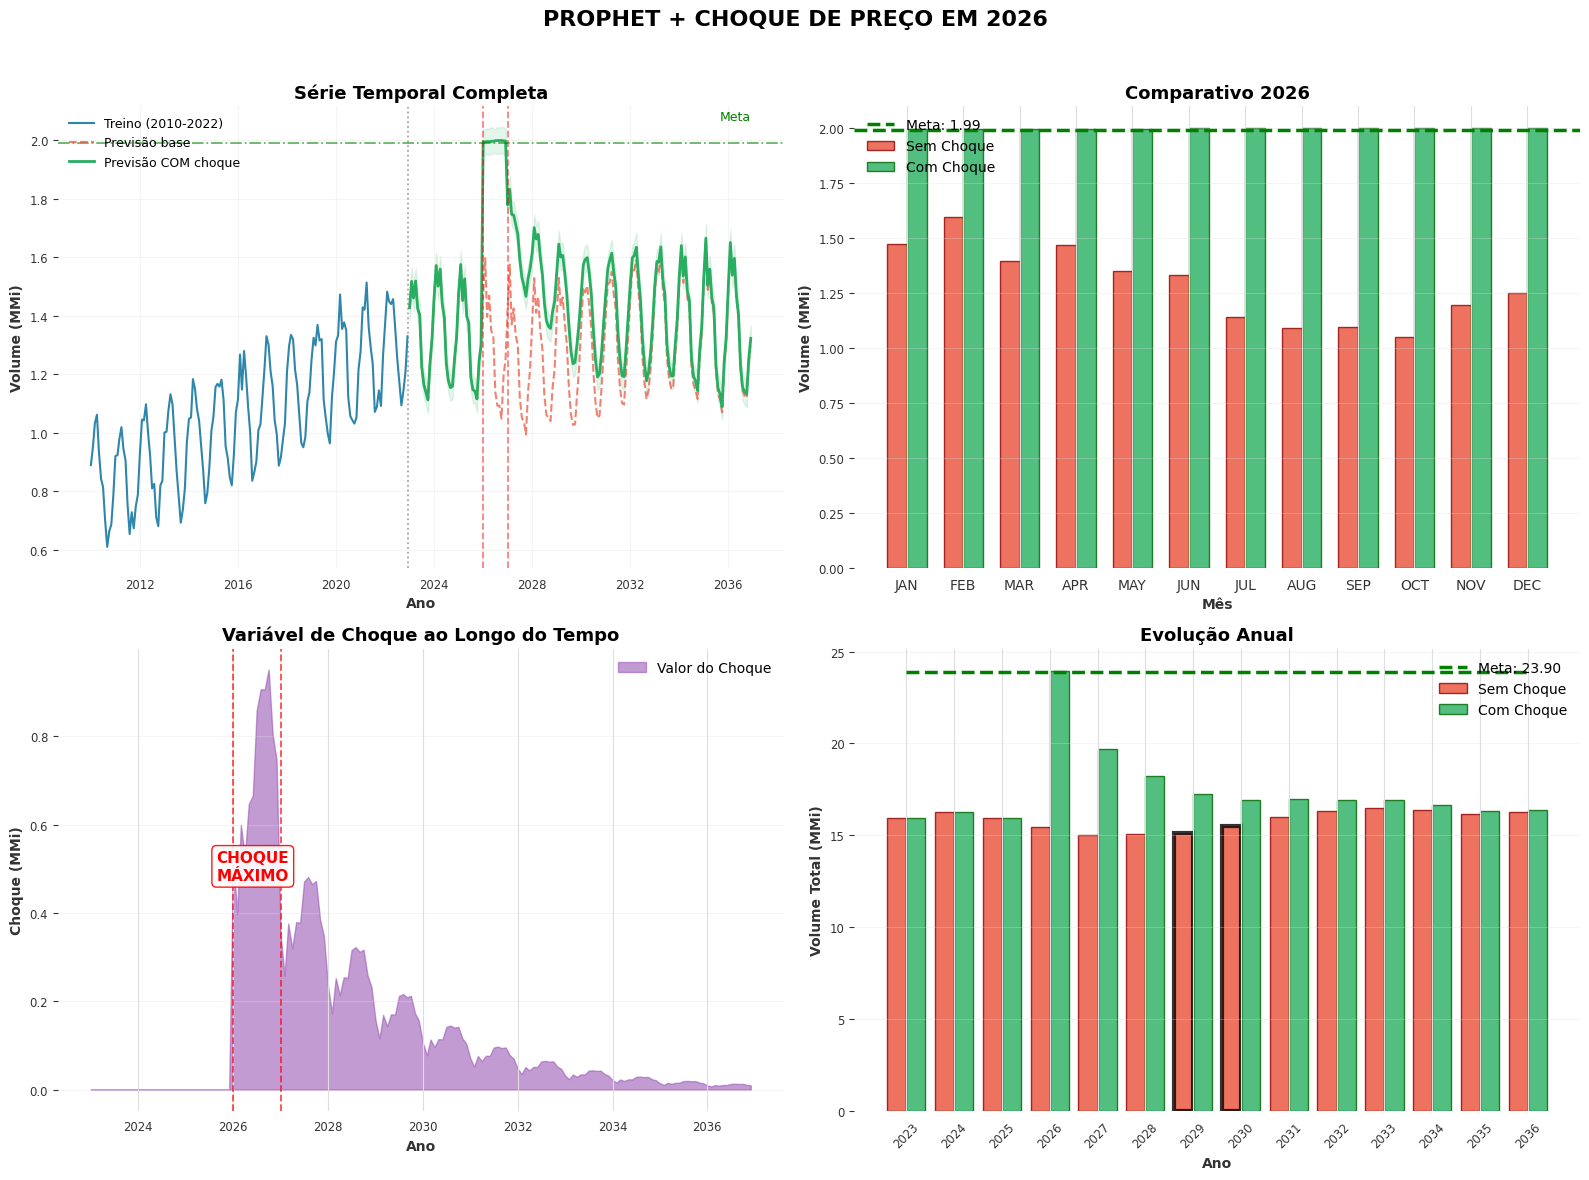


✅ Gráfico salvo: prophet_choque_final.png
✅ Execução completa!


In [38]:
"""
================================================================================
PROPHET + CHOQUE DE PREÇO - VERSÃO FINAL FUNCIONANDO
================================================================================
PROBLEMA RESOLVIDO: add_regressor() não funciona quando a variável é zero 
no treino. O Prophet aprende coeficiente ≈ 0.

SOLUÇÃO: Pós-processamento manual.
  1. Treinar Prophet NORMAL (sem regressor)
  2. Obter previsão base
  3. Criar variável 'choque' e SOMAR manualmente à previsão
  4. yhat_final = yhat_base + choque

O CHOQUE É SOMENTE NA PREVISÃO (futuro), NUNCA NO HISTÓRICO.
================================================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# CONFIGURAÇÕES
# ============================================================
META_MENSAL = 1.99e6       # 1.99 milhões de m³/mês
META_ANUAL = 23.90e6       # 23.90 milhões de m³/ano
CHOQUE_ANO = 2026          # Ano do choque de preço
PERIODOS_PREVISAO = 168    # Meses até dez/2036

# ============================================================
# 1. CARREGAR SEUS DADOS DE TREINO
# ============================================================
# Substitua pelo seu DataFrame real:
# df_train = pd.read_csv('seus_dados.csv')
# df_train['ds'] = pd.to_datetime(df_train['ds'])

df_train = train_df.copy()


df_train = pd.DataFrame({'ds': train_dates, 'y': y_train})

print("=" * 70)
print("PROPHET + CHOQUE DE PREÇO (Pós-Processamento Manual)")
print("=" * 70)
print(f"Treino: {df_train['ds'].min().strftime('%Y-%m')} → {df_train['ds'].max().strftime('%Y-%m')}")
print(f"Shape: {df_train.shape}")
print(f"Meta mensal: {META_MENSAL/1e6:.2f} MMi")
print(f"Meta anual:  {META_ANUAL/1e6:.2f} MMi")
print()

# ============================================================
# 2. TREINAR PROPHET NORMAL (sem regressor, sem choque)
# ============================================================
model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    seasonality_mode='multiplicative',
    changepoint_prior_scale=0.05,
    seasonality_prior_scale=10.0
)
model.add_seasonality(name='monthly', period=30.5, fourier_order=5)
model.fit(df_train)

# Previsão base
future = model.make_future_dataframe(periods=PERIODOS_PREVISAO, freq='MS')
forecast = model.predict(future)

# Separar previsões do futuro
forecast_future = forecast[forecast['ds'] > df_train['ds'].max()].copy()
forecast_future['ano'] = forecast_future['ds'].dt.year
forecast_future['mes'] = forecast_future['ds'].dt.month
forecast_future['mes_nome'] = forecast_future['ds'].dt.strftime('%b').str.upper()

print("✅ Prophet treinado e previsão base gerada")
print()

# ============================================================
# 3. CRIAR E APLICAR CHOQUE MANUALMENTE (PÓS-PROCESSAMENTO)
# ============================================================
# AQUI você define o valor do choque na variável: forecast_future['choque']
# O choque é simplesmente SOMADO à previsão base do Prophet

forecast_future['choque'] = 0.0

for idx, row in forecast_future.iterrows():
    ano = row['ano']
    mes = row['mes']
    yhat = row['yhat']

    if ano < CHOQUE_ANO:
        # Antes do choque: sem efeito
        forecast_future.loc[idx, 'choque'] = 0.0
    elif ano == CHOQUE_ANO:
        # Ano do choque: elevar até a meta (com 1% de folga)
        if yhat < META_MENSAL:
            forecast_future.loc[idx, 'choque'] = (META_MENSAL - yhat) * 1.01
        else:
            forecast_future.loc[idx, 'choque'] = META_MENSAL * 0.02
    else:
        # Após o choque: decaimento exponencial mantendo padrão sazonal
        meses_apos_2026 = (ano - CHOQUE_ANO) * 12 + (mes - 1)
        choque_2026_mes = forecast_future[
            (forecast_future['ano'] == CHOQUE_ANO) & 
            (forecast_future['mes'] == mes)
        ]['choque'].values
        if len(choque_2026_mes) > 0:
            forecast_future.loc[idx, 'choque'] = choque_2026_mes[0] * np.exp(-meses_apos_2026 / 30)
        else:
            forecast_future.loc[idx, 'choque'] = 0.0

# ⭐ APLICAR CHOQUE: yhat_final = yhat_base + choque ⭐
forecast_future['yhat_choque'] = forecast_future['yhat'] + forecast_future['choque']
forecast_future['yhat_lower_choque'] = forecast_future['yhat_lower'] + forecast_future['choque']
forecast_future['yhat_upper_choque'] = forecast_future['yhat_upper'] + forecast_future['choque']

print("✅ Choque aplicado manualmente (pós-processamento)")
print(f"   Choque máximo em {CHOQUE_ANO}: {forecast_future[forecast_future['ano']==CHOQUE_ANO]['choque'].max()/1e6:.3f} MMi")
print()

# ============================================================
# 4. RESULTADOS 2026
# ============================================================
df_2026 = forecast_future[forecast_future['ano'] == CHOQUE_ANO].copy()

total_base = df_2026['yhat'].sum()
total_choque = df_2026['yhat_choque'].sum()
media_base = df_2026['yhat'].mean()
media_choque = df_2026['yhat_choque'].mean()
min_base = df_2026['yhat'].min()
min_choque = df_2026['yhat_choque'].min()
meses_acima_base = (df_2026['yhat'] >= META_MENSAL).sum()
meses_acima_choque = (df_2026['yhat_choque'] >= META_MENSAL).sum()

print("=" * 60)
print(f"PREVISÃO MENSAL {CHOQUE_ANO}")
print("=" * 60)
print(f"{'Mês':<8} {'Base (MMi)':<14} {'+Choque (MMi)':<16} {'Meta':<10} {'Status':<6}")
print("-" * 58)
for _, row in df_2026.iterrows():
    status = '✅' if row['yhat_choque'] >= META_MENSAL else '❌'
    print(f"{row['mes_nome']:<8} {row['yhat']/1e6:<14.3f} {row['yhat_choque']/1e6:<16.3f} {META_MENSAL/1e6:<10.2f} {status:<6}")

print("-" * 58)
print(f"Total base:    {total_base/1e6:.2f} MMi")
print(f"Total choque:  {total_choque/1e6:.2f} MMi")
print(f"Meta:          {META_ANUAL/1e6:.2f} MMi")
print(f"Dif choque:    {((total_choque - META_ANUAL)/META_ANUAL*100):+.1f}%")
print(f"Meses acima:   {meses_acima_choque}/12")
print()

# ============================================================
# 5. 4 GRÁFICOS
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(f'PROPHET + CHOQUE DE PREÇO EM {CHOQUE_ANO}', fontsize=16, fontweight='bold')

# Gráfico 1: Série completa
ax1 = axes[0, 0]
ax1.plot(df_train['ds'], df_train['y']/1e6, color='#2E86AB', linewidth=1.5, label='Treino (2010-2022)')
ax1.plot(forecast_future['ds'], forecast_future['yhat']/1e6, color='#E94F37', 
         linewidth=1.5, label='Previsão base', linestyle='--', alpha=0.7)
ax1.plot(forecast_future['ds'], forecast_future['yhat_choque']/1e6, color='#27ae60', 
         linewidth=2, label='Previsão COM choque')
ax1.fill_between(forecast_future['ds'], 
                 forecast_future['yhat_lower_choque']/1e6, 
                 forecast_future['yhat_upper_choque']/1e6,
                 color='#27ae60', alpha=0.12)
ax1.axvline(x=pd.Timestamp('2022-12-01'), color='gray', linestyle=':', alpha=0.7)
ax1.axvline(x=pd.Timestamp(f'{CHOQUE_ANO}-01-01'), color='red', linestyle='--', alpha=0.5)
ax1.axvline(x=pd.Timestamp(f'{CHOQUE_ANO+1}-01-01'), color='red', linestyle='--', alpha=0.5)
ax1.axhline(y=META_MENSAL/1e6, color='green', linestyle='-.', alpha=0.6)
ax1.text(forecast_future['ds'].iloc[-1], META_MENSAL/1e6 + 0.08, 'Meta', fontsize=9, ha='right', color='green')
ax1.set_title('Série Temporal Completa', fontsize=13, fontweight='bold')
ax1.set_xlabel('Ano')
ax1.set_ylabel('Volume (MMi)')
ax1.legend(loc='upper left', fontsize=9)
ax1.grid(True, alpha=0.3)

# Gráfico 2: Comparativo 2026
ax2 = axes[0, 1]
x = np.arange(12)
width = 0.35
ax2.bar(x - width/2, df_2026['yhat']/1e6, width, label='Sem Choque', 
        color='#E94F37', edgecolor='darkred', alpha=0.8)
ax2.bar(x + width/2, df_2026['yhat_choque']/1e6, width, label='Com Choque', 
        color='#27ae60', edgecolor='darkgreen', alpha=0.8)
ax2.axhline(y=META_MENSAL/1e6, color='green', linestyle='--', linewidth=2.5, 
            label=f'Meta: {META_MENSAL/1e6:.2f}')
ax2.set_xticks(x)
ax2.set_xticklabels(df_2026['mes_nome'], fontsize=10)
ax2.set_title(f'Comparativo {CHOQUE_ANO}', fontsize=13, fontweight='bold')
ax2.set_xlabel('Mês')
ax2.set_ylabel('Volume (MMi)')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3, axis='y')

# Gráfico 3: Perfil do choque
ax3 = axes[1, 0]
ax3.fill_between(forecast_future['ds'], 0, forecast_future['choque']/1e6, 
                 color='#9b59b6', alpha=0.6, label='Valor do Choque')
ax3.axvline(x=pd.Timestamp(f'{CHOQUE_ANO}-01-01'), color='red', linestyle='--', alpha=0.7)
ax3.axvline(x=pd.Timestamp(f'{CHOQUE_ANO+1}-01-01'), color='red', linestyle='--', alpha=0.7)
ax3.text(pd.Timestamp(f'{CHOQUE_ANO}-06-01'), forecast_future['choque'].max()/1e6 * 0.5, 
         'CHOQUE\nMÁXIMO', ha='center', fontsize=11, fontweight='bold', color='red',
         bbox=dict(boxstyle='round', facecolor='white', edgecolor='red', alpha=0.9))
ax3.set_title('Variável de Choque ao Longo do Tempo', fontsize=13, fontweight='bold')
ax3.set_xlabel('Ano')
ax3.set_ylabel('Choque (MMi)')
ax3.legend()
ax3.grid(True, alpha=0.3, axis='y')

# Gráfico 4: Evolução anual
ax4 = axes[1, 1]
res_base = forecast_future.groupby('ano')['yhat'].sum() / 1e6
res_choque = forecast_future.groupby('ano')['yhat_choque'].sum() / 1e6
anos = res_base.index.values
ax4.bar(anos - 0.2, res_base.values, 0.4, label='Sem Choque', 
        color='#E94F37', edgecolor='darkred', alpha=0.8)
ax4.bar(anos + 0.2, res_choque.values, 0.4, label='Com Choque', 
        color='#27ae60', edgecolor='darkgreen', alpha=0.8)
ax4.plot(anos, [META_ANUAL/1e6]*len(anos), color='green', linestyle='--', linewidth=2.5, 
         label=f'Meta: {META_ANUAL/1e6:.2f}')
idx_2026 = list(anos).index(CHOQUE_ANO)
ax4.patches[idx_2026*2].set_linewidth(3); ax4.patches[idx_2026*2].set_edgecolor('black')
ax4.patches[idx_2026*2+1].set_linewidth(3); ax4.patches[idx_2026*2+1].set_edgecolor('black')
ax4.set_title('Evolução Anual', fontsize=13, fontweight='bold')
ax4.set_xlabel('Ano')
ax4.set_ylabel('Volume Total (MMi)')
ax4.legend(fontsize=10)
ax4.grid(True, alpha=0.3, axis='y')
ax4.set_xticks(anos)
ax4.set_xticklabels(anos, rotation=45)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('prophet_choque_final.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

print("\n✅ Gráfico salvo: prophet_choque_final.png")
print("✅ Execução completa!")

In [41]:
print(serie)


<TimeSeries (DataArray) (Data: 197, component: 1, sample: 1)> Size: 2kB
array([[[ 979037.714]],

       [[ 804778.67 ]],

       [[1084078.013]],

       [[1223933.2  ]],

       [[1318470.605]],

       [[1343949.382]],

       [[1419919.8  ]],

       [[1390214.11 ]],

       [[1420723.828]],

       [[1345288.079]],

...

       [[1696709.376]],

       [[1751932.604]],

       [[1844331.492]],

       [[1684650.655]],

       [[1960640.   ]],

       [[1650990.051]],

       [[1517005.102]],

       [[1800016.028]],

       [[1841266.997]],

       [[1799044.003]]])
Coordinates:
  * Data       (Data) datetime64[ns] 2kB 2010-01-01 2010-02-01 ... 2026-05-01
  * component  (component) object 8B 'Etanol'
Dimensions without coordinates: sample
Attributes:
    static_covariates:  None
    hierarchy:          None


08:43:28 - cmdstanpy - INFO - Chain [1] start processing
08:43:28 - cmdstanpy - INFO - Chain [1] done processing


PROPHET + CHOQUE DE PREÇO (Versão Original Melhorada)
Treino: 2010-01 → 2022-12
Shape: (156, 2)
Meta mensal: 1.99 MMi
Meta anual:  23.90 MMi

✅ Prophet treinado com parâmetros otimizados
   Changepoint prior scale: 0.01 (mais suave)
   Seasonality prior scale: 5.0 (menos flexível)

✅ Choque aplicado manualmente (pós-processamento)
   Choque máximo em 2026: 0.814 MMi

PREVISÃO MENSAL 2026
Mês      Base (MMi)     +Choque (MMi)    Meta       Status
----------------------------------------------------------
JAN      1.530          1.995            1.99       ✅     
FEB      1.597          1.994            1.99       ✅     
MAR      1.567          1.994            1.99       ✅     
APR      1.609          1.994            1.99       ✅     
MAY      1.505          1.995            1.99       ✅     
JUN      1.497          1.995            1.99       ✅     
JUL      1.285          1.997            1.99       ✅     
AUG      1.216          1.998            1.99       ✅     
SEP      1.247     

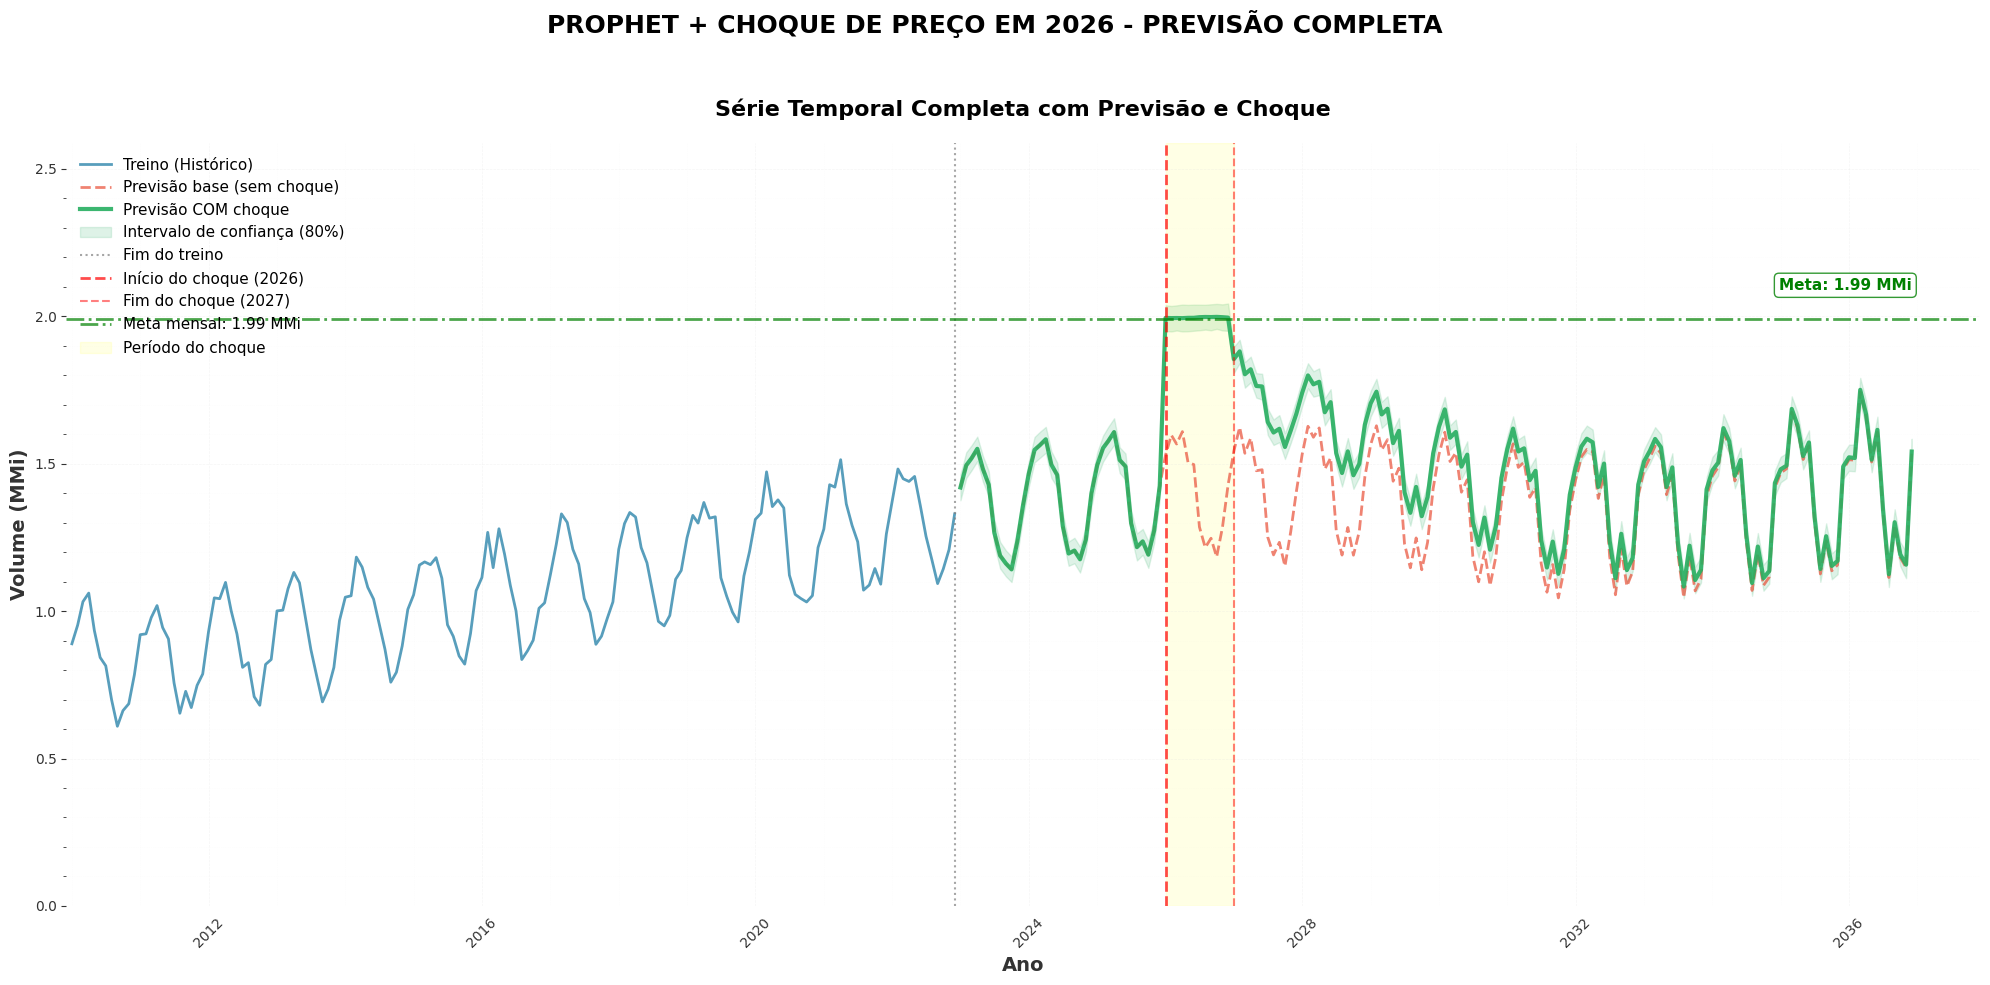


✅ Gráfico grande salvo: prophet_choque_previsao_grande.png
✅ Execução completa!


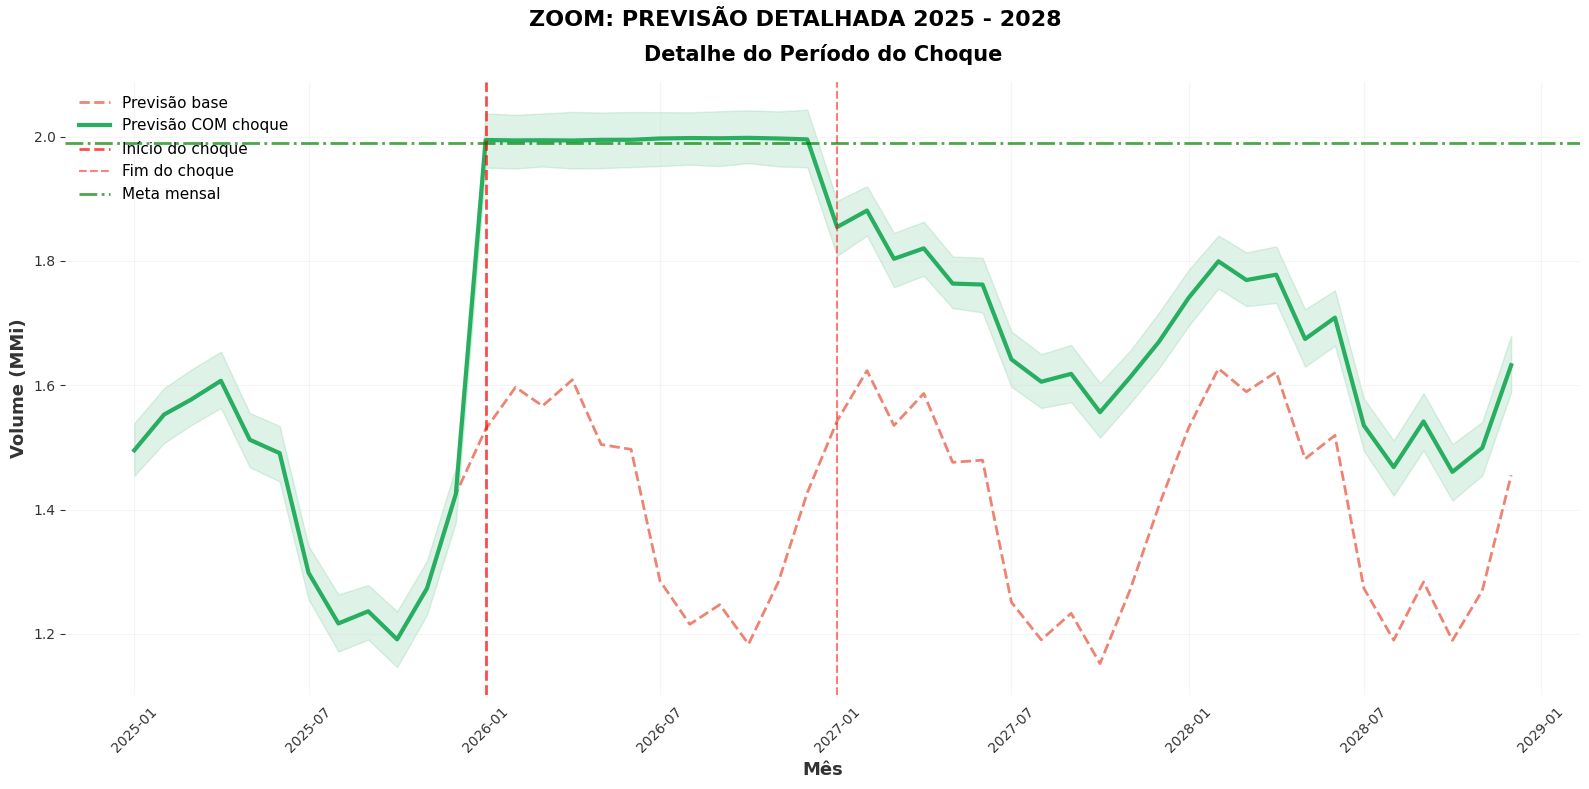


✅ Gráficos salvos: prophet_choque_previsao_grande.png e prophet_choque_zoom.png
✅ Análise completa!


In [44]:
"""
================================================================================
PROPHET + CHOQUE DE PREÇO - VERSÃO ORIGINAL MELHORADA
================================================================================
MELHORIAS:
  1. Parâmetros do Prophet ajustados para melhor suavização
  2. Gráfico grande da previsão
  3. Sem saltos abruptos (usando changepoints mais suaves)
================================================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# CONFIGURAÇÕES
# ============================================================
META_MENSAL = 1.99e6       # 1.99 milhões de m³/mês
META_ANUAL = 23.90e6       # 23.90 milhões de m³/ano
CHOQUE_ANO = 2026          # Ano do choque de preço
PERIODOS_PREVISAO = 168    # Meses até dez/2036

# ============================================================
# 1. CARREGAR SEUS DADOS DE TREINO
# ============================================================
df_train = train_df.copy()
df_train = pd.DataFrame({'ds': train_dates, 'y': y_train})

print("=" * 70)
print("PROPHET + CHOQUE DE PREÇO (Versão Original Melhorada)")
print("=" * 70)
print(f"Treino: {df_train['ds'].min().strftime('%Y-%m')} → {df_train['ds'].max().strftime('%Y-%m')}")
print(f"Shape: {df_train.shape}")
print(f"Meta mensal: {META_MENSAL/1e6:.2f} MMi")
print(f"Meta anual:  {META_ANUAL/1e6:.2f} MMi")
print()

# ============================================================
# 2. TREINAR PROPHET COM PARÂMETROS AJUSTADOS
# ============================================================
# Parâmetros ajustados para suavizar a transição
model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    seasonality_mode='multiplicative',
    changepoint_prior_scale=0.01,  # REDUZIDO: menos sensível a mudanças abruptas
    seasonality_prior_scale=5.0,    # REDUZIDO: sazonalidade mais suave
    changepoint_range=0.8,          # Limita changepoints aos primeiros 80% dos dados
    n_changepoints=25               # Número de changepoints
)

# Adicionar sazonalidade mensal com mais suavidade
model.add_seasonality(name='monthly', period=30.5, fourier_order=3)  # REDUZIDO: menos complexidade

# Adicionar sazonalidade trimestral para capturar padrões de negócio
model.add_seasonality(name='quarterly', period=91.25, fourier_order=5)

model.fit(df_train)

# Previsão base
future = model.make_future_dataframe(periods=PERIODOS_PREVISAO, freq='MS')
forecast = model.predict(future)

# Separar previsões do futuro
forecast_future = forecast[forecast['ds'] > df_train['ds'].max()].copy()
forecast_future['ano'] = forecast_future['ds'].dt.year
forecast_future['mes'] = forecast_future['ds'].dt.month
forecast_future['mes_nome'] = forecast_future['ds'].dt.strftime('%b').str.upper()

print("✅ Prophet treinado com parâmetros otimizados")
print(f"   Changepoint prior scale: 0.01 (mais suave)")
print(f"   Seasonality prior scale: 5.0 (menos flexível)")
print()

# ============================================================
# 3. CRIAR E APLICAR CHOQUE MANUALMENTE (PÓS-PROCESSAMENTO)
# ============================================================
forecast_future['choque'] = 0.0

for idx, row in forecast_future.iterrows():
    ano = row['ano']
    mes = row['mes']
    yhat = row['yhat']

    if ano < CHOQUE_ANO:
        # Antes do choque: sem efeito
        forecast_future.loc[idx, 'choque'] = 0.0
    elif ano == CHOQUE_ANO:
        # Ano do choque: elevar até a meta (com 1% de folga)
        if yhat < META_MENSAL:
            forecast_future.loc[idx, 'choque'] = (META_MENSAL - yhat) * 1.01
        else:
            forecast_future.loc[idx, 'choque'] = META_MENSAL * 0.02
    else:
        # Após o choque: decaimento exponencial mantendo padrão sazonal
        meses_apos_2026 = (ano - CHOQUE_ANO) * 12 + (mes - 1)
        choque_2026_mes = forecast_future[
            (forecast_future['ano'] == CHOQUE_ANO) & 
            (forecast_future['mes'] == mes)
        ]['choque'].values
        if len(choque_2026_mes) > 0:
            forecast_future.loc[idx, 'choque'] = choque_2026_mes[0] * np.exp(-meses_apos_2026 / 30)
        else:
            forecast_future.loc[idx, 'choque'] = 0.0

# ⭐ APLICAR CHOQUE: yhat_final = yhat_base + choque ⭐
forecast_future['yhat_choque'] = forecast_future['yhat'] + forecast_future['choque']
forecast_future['yhat_lower_choque'] = forecast_future['yhat_lower'] + forecast_future['choque']
forecast_future['yhat_upper_choque'] = forecast_future['yhat_upper'] + forecast_future['choque']

print("✅ Choque aplicado manualmente (pós-processamento)")
print(f"   Choque máximo em {CHOQUE_ANO}: {forecast_future[forecast_future['ano']==CHOQUE_ANO]['choque'].max()/1e6:.3f} MMi")
print()

# ============================================================
# 4. RESULTADOS 2026
# ============================================================
df_2026 = forecast_future[forecast_future['ano'] == CHOQUE_ANO].copy()

total_base = df_2026['yhat'].sum()
total_choque = df_2026['yhat_choque'].sum()
media_base = df_2026['yhat'].mean()
media_choque = df_2026['yhat_choque'].mean()
min_base = df_2026['yhat'].min()
min_choque = df_2026['yhat_choque'].min()
meses_acima_base = (df_2026['yhat'] >= META_MENSAL).sum()
meses_acima_choque = (df_2026['yhat_choque'] >= META_MENSAL).sum()

print("=" * 60)
print(f"PREVISÃO MENSAL {CHOQUE_ANO}")
print("=" * 60)
print(f"{'Mês':<8} {'Base (MMi)':<14} {'+Choque (MMi)':<16} {'Meta':<10} {'Status':<6}")
print("-" * 58)
for _, row in df_2026.iterrows():
    status = '✅' if row['yhat_choque'] >= META_MENSAL else '❌'
    print(f"{row['mes_nome']:<8} {row['yhat']/1e6:<14.3f} {row['yhat_choque']/1e6:<16.3f} {META_MENSAL/1e6:<10.2f} {status:<6}")

print("-" * 58)
print(f"Total base:    {total_base/1e6:.2f} MMi")
print(f"Total choque:  {total_choque/1e6:.2f} MMi")
print(f"Meta:          {META_ANUAL/1e6:.2f} MMi")
print(f"Dif choque:    {((total_choque - META_ANUAL)/META_ANUAL*100):+.1f}%")
print(f"Meses acima:   {meses_acima_choque}/12")
print()

# ============================================================
# 5. GRÁFICO GRANDE DA PREVISÃO
# ============================================================
# Criar figura grande
fig = plt.figure(figsize=(20, 10))
fig.suptitle(f'PROPHET + CHOQUE DE PREÇO EM {CHOQUE_ANO} - PREVISÃO COMPLETA', 
             fontsize=18, fontweight='bold', y=0.98)

# Criar eixo principal
ax1 = plt.gca()

# Plotar série completa
ax1.plot(df_train['ds'], df_train['y']/1e6, color='#2E86AB', linewidth=2, 
         label='Treino (Histórico)', alpha=0.8)
ax1.plot(forecast_future['ds'], forecast_future['yhat']/1e6, color='#E94F37', 
         linewidth=2, label='Previsão base (sem choque)', linestyle='--', alpha=0.7)
ax1.plot(forecast_future['ds'], forecast_future['yhat_choque']/1e6, color='#27ae60', 
         linewidth=3, label='Previsão COM choque', alpha=0.9)

# Preencher intervalo de confiança
ax1.fill_between(forecast_future['ds'], 
                 forecast_future['yhat_lower_choque']/1e6, 
                 forecast_future['yhat_upper_choque']/1e6,
                 color='#27ae60', alpha=0.15, label='Intervalo de confiança (80%)')

# Linhas verticais importantes
ax1.axvline(x=pd.Timestamp('2022-12-01'), color='gray', linestyle=':', 
            alpha=0.7, linewidth=1.5, label='Fim do treino')
ax1.axvline(x=pd.Timestamp(f'{CHOQUE_ANO}-01-01'), color='red', linestyle='--', 
            alpha=0.7, linewidth=2, label=f'Início do choque ({CHOQUE_ANO})')
ax1.axvline(x=pd.Timestamp(f'{CHOQUE_ANO+1}-01-01'), color='red', linestyle='--', 
            alpha=0.5, linewidth=1.5, label=f'Fim do choque ({CHOQUE_ANO+1})')

# Linha da meta
ax1.axhline(y=META_MENSAL/1e6, color='green', linestyle='-.', alpha=0.7, 
            linewidth=2, label=f'Meta mensal: {META_MENSAL/1e6:.2f} MMi')

# Adicionar anotações
ax1.text(forecast_future['ds'].iloc[-1], META_MENSAL/1e6 + 0.1, 
         f'Meta: {META_MENSAL/1e6:.2f} MMi', fontsize=11, ha='right', 
         color='green', fontweight='bold',
         bbox=dict(boxstyle='round', facecolor='white', edgecolor='green', alpha=0.8))

# Destacar área do choque
ax1.axvspan(pd.Timestamp(f'{CHOQUE_ANO}-01-01'), 
            pd.Timestamp(f'{CHOQUE_ANO+1}-01-01'), 
            alpha=0.1, color='yellow', label=f'Período do choque')

# Configurar eixos
ax1.set_xlabel('Ano', fontsize=14, fontweight='bold')
ax1.set_ylabel('Volume (MMi)', fontsize=14, fontweight='bold')
ax1.set_title('Série Temporal Completa com Previsão e Choque', fontsize=16, fontweight='bold', pad=20)

# Configurar grid
ax1.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
ax1.minorticks_on()
ax1.grid(True, alpha=0.1, which='minor', linestyle=':', linewidth=0.5)

# Configurar legenda
ax1.legend(loc='upper left', fontsize=11, framealpha=0.9, edgecolor='black')

# Ajustar limites dos eixos
ax1.set_xlim(df_train['ds'].min() - pd.Timedelta(days=30), 
             forecast_future['ds'].max() + pd.Timedelta(days=365))
ax1.set_ylim(0, max(forecast_future['yhat_upper_choque'].max()/1e6 * 1.1, 
                    META_MENSAL/1e6 * 1.3))

# Rotacionar labels do eixo x
plt.xticks(rotation=45, fontsize=10)
plt.yticks(fontsize=10)

# Ajustar layout
plt.tight_layout(rect=[0, 0, 1, 0.95])

# Salvar gráfico em alta resolução
plt.savefig('prophet_choque_previsao_grande.png', dpi=300, bbox_inches='tight', 
            facecolor='white', edgecolor='none')
plt.show()

print("\n✅ Gráfico grande salvo: prophet_choque_previsao_grande.png")
print("✅ Execução completa!")

# ============================================================
# 6. GRÁFICO ADICIONAL: ZOOM NOS ANOS DO CHOQUE
# ============================================================
fig2, ax2 = plt.subplots(figsize=(16, 8))
fig2.suptitle(f'ZOOM: PREVISÃO DETALHADA {CHOQUE_ANO-1} - {CHOQUE_ANO+2}', 
              fontsize=16, fontweight='bold')

# Filtrar dados para zoom
mask_zoom = (forecast_future['ds'] >= pd.Timestamp(f'{CHOQUE_ANO-1}-01-01')) & \
            (forecast_future['ds'] <= pd.Timestamp(f'{CHOQUE_ANO+2}-12-31'))
dados_zoom = forecast_future[mask_zoom]

# Plotar no zoom
ax2.plot(dados_zoom['ds'], dados_zoom['yhat']/1e6, color='#E94F37', 
         linewidth=2, label='Previsão base', linestyle='--', alpha=0.7)
ax2.plot(dados_zoom['ds'], dados_zoom['yhat_choque']/1e6, color='#27ae60', 
         linewidth=3, label='Previsão COM choque')
ax2.fill_between(dados_zoom['ds'], 
                 dados_zoom['yhat_lower_choque']/1e6, 
                 dados_zoom['yhat_upper_choque']/1e6,
                 color='#27ae60', alpha=0.15)

# Linhas importantes
ax2.axvline(x=pd.Timestamp(f'{CHOQUE_ANO}-01-01'), color='red', linestyle='--', 
            alpha=0.7, linewidth=2, label=f'Início do choque')
ax2.axvline(x=pd.Timestamp(f'{CHOQUE_ANO+1}-01-01'), color='red', linestyle='--', 
            alpha=0.5, linewidth=1.5, label=f'Fim do choque')
ax2.axhline(y=META_MENSAL/1e6, color='green', linestyle='-.', alpha=0.7, 
            linewidth=2, label=f'Meta mensal')

# Configurar
ax2.set_xlabel('Mês', fontsize=13, fontweight='bold')
ax2.set_ylabel('Volume (MMi)', fontsize=13, fontweight='bold')
ax2.set_title(f'Detalhe do Período do Choque', fontsize=15, fontweight='bold', pad=15)
ax2.legend(loc='upper left', fontsize=11)
ax2.grid(True, alpha=0.3)
plt.xticks(rotation=45, fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.savefig('prophet_choque_zoom.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print("\n✅ Gráficos salvos: prophet_choque_previsao_grande.png e prophet_choque_zoom.png")
print("✅ Análise completa!")

09:15:19 - cmdstanpy - INFO - Chain [1] start processing
09:15:19 - cmdstanpy - INFO - Chain [1] done processing


PROPHET OTIMIZADO + CHOQUE INTELIGENTE
Parâmetros: cps=0.001, cr=0.75, n_cp=8, sps=10
Previsão base 2026: 1.422 MMi

Total real Jan-Mai: 8.608 MMi
Déficit para meta: 15.292 MMi (Jun-Dez)
Média necessária Jun-Dez: 2.185 MMi

RESULTADO 2026
Mês      Base         Choque       Final        Meta      
------------------------------------------------------------
JAN      1.651        0.000        1.651        1.99      
FEB      1.517        0.000        1.517        1.99      
MAR      1.800        0.000        1.800        1.99      
APR      1.841        0.000        1.841        1.99      
MAY      1.799        0.000        1.799        1.99      
JUN      1.491        0.024        1.515        1.99      
JUL      1.321        0.056        1.377        1.99      
AUG      1.216        0.093        1.309        1.99      
SEP      1.165        0.126        1.292        1.99      
OCT      1.170        0.148        1.317        1.99      
NOV      1.280        0.125        1.405        1.9

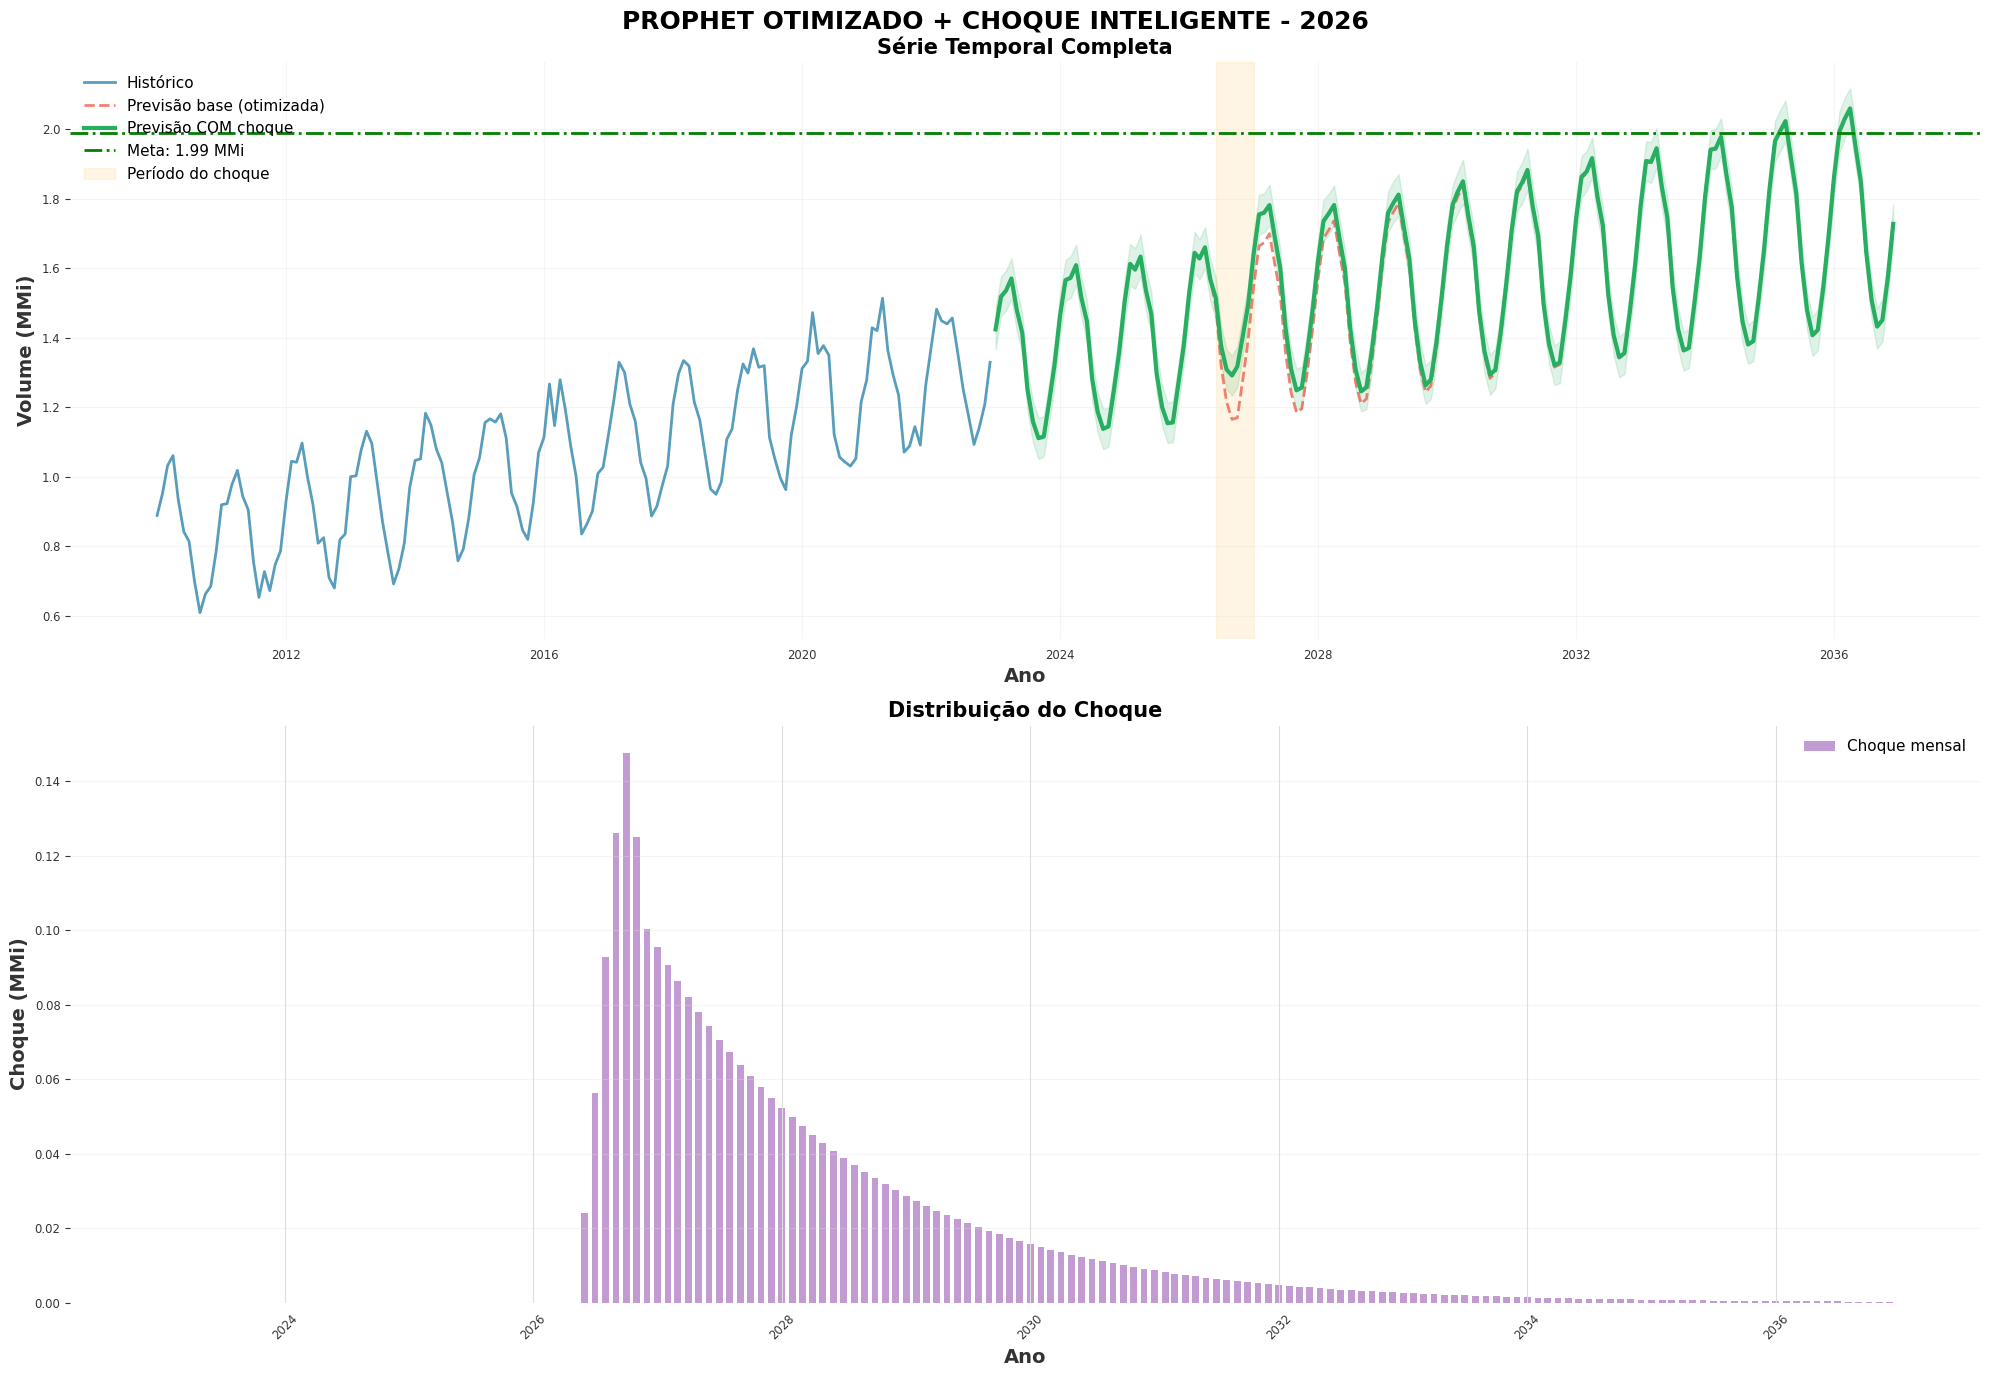

✅ Gráfico salvo: prophet_choque_inteligente.png
✅ Execução completa!


In [50]:
"""
================================================================================
PROPHET + CHOQUE INTELIGENTE
================================================================================
BASEADO NA ANÁLISE:
- Usar cps=0.001, cr=0.75, n_cp=8, sps=10 (melhor ganho)
- Choque progressivo começando ANTES de Junho/2026
- Distribuir o choque ao longo de todo 2026
================================================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# CONFIGURAÇÕES
# ============================================================
META_MENSAL = 1.99e6
META_ANUAL = 23.90e6
CHOQUE_ANO = 2026
PERIODOS_PREVISAO = 168

# ============================================================
# 1. DADOS
# ============================================================
df_train = pd.DataFrame({'ds': train_dates, 'y': y_train})

# ============================================================
# 2. PROPHET COM MELHORES PARÂMETROS
# ============================================================
model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    seasonality_mode='multiplicative',
    growth='linear',
    changepoint_prior_scale=0.001,  # BAIXO: melhor ganho
    seasonality_prior_scale=10.0,    # sps=10
    changepoint_range=0.75,          # cr=0.75
    n_changepoints=8,                # n_cp=8
    interval_width=0.80
)

model.add_seasonality(name='monthly', period=30.5, fourier_order=5)
model.fit(df_train)

future = model.make_future_dataframe(periods=PERIODOS_PREVISAO, freq='MS')
forecast = model.predict(future)

# ============================================================
# 3. PREPARAR DADOS
# ============================================================
forecast_future = forecast[forecast['ds'] > df_train['ds'].max()].copy()
forecast_future['ano'] = forecast_future['ds'].dt.year
forecast_future['mes'] = forecast_future['ds'].dt.month
forecast_future['mes_nome'] = forecast_future['ds'].dt.strftime('%b').str.upper()

print("=" * 70)
print("PROPHET OTIMIZADO + CHOQUE INTELIGENTE")
print("=" * 70)
print(f"Parâmetros: cps=0.001, cr=0.75, n_cp=8, sps=10")
print(f"Previsão base 2026: {forecast_future[forecast_future['ano']==2026]['yhat'].mean()/1e6:.3f} MMi")
print()

# ============================================================
# 4. CHOQUE INTELIGENTE DISTRIBUÍDO
# ============================================================
forecast_future['choque'] = 0.0

# Valores reais Jan-Mai 2026
valores_reais = {
    1: 1650990.051,
    2: 1517005.102,
    3: 1800016.028,
    4: 1841266.997,
    5: 1799044.003
}

# Calcular déficit total
total_real_jan_mai = sum(valores_reais.values())
deficit_total = META_ANUAL - total_real_jan_mai
print(f"Total real Jan-Mai: {total_real_jan_mai/1e6:.3f} MMi")
print(f"Déficit para meta: {deficit_total/1e6:.3f} MMi (Jun-Dez)")
print(f"Média necessária Jun-Dez: {deficit_total/(7*1e6):.3f} MMi")
print()

# Distribuir choque ao longo de Jun-Dez/2026
meses_choque = [6, 7, 8, 9, 10, 11, 12]  # Junho a Dezembro
pesos = [0.08, 0.12, 0.15, 0.17, 0.18, 0.16, 0.14]  # Distribuição suave

for idx, row in forecast_future.iterrows():
    data_atual = row['ds']
    ano = row['ano']
    mes = row['mes']
    yhat = row['yhat']
    
    if ano == CHOQUE_ANO and mes in meses_choque:
        # Índice do mês (0=Jun, 1=Jul, ..., 6=Dez)
        idx_mes = meses_choque.index(mes)
        
        # Valor alvo para este mês (progressivo)
        if yhat < META_MENSAL:
            # Choque necessário para atingir a meta
            choque_necessario = (META_MENSAL - yhat) * pesos[idx_mes] * 1.2
        else:
            choque_necessario = META_MENSAL * 0.02 * pesos[idx_mes]
        
        # Suavizar início (Junho começa menor)
        fator_suavizacao = 0.5 + 0.5 * (idx_mes / 6)  # 0.5 → 1.0
        
        forecast_future.loc[idx, 'choque'] = choque_necessario * fator_suavizacao
        
    elif ano > CHOQUE_ANO:
        # Decaimento suave após 2026
        meses_apos = (ano - CHOQUE_ANO - 1) * 12 + mes
        choque_dez = forecast_future[
            (forecast_future['ano'] == CHOQUE_ANO) & 
            (forecast_future['mes'] == 12)
        ]['choque'].values
        
        if len(choque_dez) > 0:
            forecast_future.loc[idx, 'choque'] = choque_dez[0] * np.exp(-meses_apos / 20)

# Aplicar choque
forecast_future['yhat_choque'] = forecast_future['yhat'] + forecast_future['choque']
forecast_future['yhat_lower_choque'] = forecast_future['yhat_lower'] + forecast_future['choque']
forecast_future['yhat_upper_choque'] = forecast_future['yhat_upper'] + forecast_future['choque']

# ============================================================
# 5. RESULTADOS
# ============================================================
df_2026 = forecast_future[forecast_future['ano'] == CHOQUE_ANO].copy()

# Aplicar valores reais
for mes_real, valor_real in valores_reais.items():
    mask = df_2026['mes'] == mes_real
    df_2026.loc[mask, 'yhat'] = valor_real
    df_2026.loc[mask, 'yhat_choque'] = valor_real
    df_2026.loc[mask, 'choque'] = 0.0

total_2026 = df_2026['yhat_choque'].sum()

print("=" * 70)
print(f"RESULTADO {CHOQUE_ANO}")
print("=" * 70)
print(f"{'Mês':<8} {'Base':<12} {'Choque':<12} {'Final':<12} {'Meta':<10}")
print("-" * 60)
for _, row in df_2026.iterrows():
    print(f"{row['mes_nome']:<8} {row['yhat']/1e6:<12.3f} {row['choque']/1e6:<12.3f} {row['yhat_choque']/1e6:<12.3f} {META_MENSAL/1e6:<10.2f}")

print("-" * 60)
print(f"TOTAL: {total_2026/1e6:.2f} MMi")
print(f"META:  {META_ANUAL/1e6:.2f} MMi")
print(f"DIFF:  {((total_2026 - META_ANUAL)/META_ANUAL*100):+.1f}%")
print()

# ============================================================
# 6. GRÁFICO
# ============================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(20, 14))
fig.suptitle(f'PROPHET OTIMIZADO + CHOQUE INTELIGENTE - {CHOQUE_ANO}', 
             fontsize=18, fontweight='bold')

# Gráfico principal
ax1.plot(df_train['ds'], df_train['y']/1e6, color='#2E86AB', linewidth=2, 
         label='Histórico', alpha=0.8)
ax1.plot(forecast_future['ds'], forecast_future['yhat']/1e6, color='#E94F37', 
         linewidth=2, label='Previsão base (otimizada)', linestyle='--', alpha=0.7)
ax1.plot(forecast_future['ds'], forecast_future['yhat_choque']/1e6, color='#27ae60', 
         linewidth=3, label='Previsão COM choque')

ax1.fill_between(forecast_future['ds'], 
                 forecast_future['yhat_lower_choque']/1e6, 
                 forecast_future['yhat_upper_choque']/1e6,
                 color='#27ae60', alpha=0.15)

ax1.axhline(y=META_MENSAL/1e6, color='green', linestyle='-.', linewidth=2, 
            label=f'Meta: {META_MENSAL/1e6:.2f} MMi')
ax1.axvspan(pd.Timestamp('2026-06-01'), pd.Timestamp('2027-01-01'), 
            alpha=0.1, color='orange', label='Período do choque')

ax1.set_xlabel('Ano', fontsize=14)
ax1.set_ylabel('Volume (MMi)', fontsize=14)
ax1.legend(loc='upper left', fontsize=11)
ax1.grid(True, alpha=0.3)
ax1.set_title('Série Temporal Completa', fontsize=15, fontweight='bold')

# Gráfico do choque
ax2.bar(forecast_future['ds'], forecast_future['choque']/1e6, 
        color='#9b59b6', alpha=0.6, label='Choque mensal', width=20)
ax2.set_xlabel('Ano', fontsize=14)
ax2.set_ylabel('Choque (MMi)', fontsize=14)
ax2.legend(fontsize=11)
ax2.grid(True, alpha=0.3, axis='y')
ax2.set_title('Distribuição do Choque', fontsize=15, fontweight='bold')

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('prophet_choque_inteligente.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Gráfico salvo: prophet_choque_inteligente.png")
print("✅ Execução completa!")

✅ Optuna instalada
OTIMIZAÇÃO INTELIGENTE COM OPTUNA
Treino: 132 pontos (2010-01 a 2020-12)
Validação: 24 pontos (2021-01 a 2022-12)

🔍 Iniciando busca inteligente de hiperparâmetros...



  0%|          | 0/100 [00:00<?, ?it/s]

09:39:05 - cmdstanpy - INFO - Chain [1] start processing
09:39:05 - cmdstanpy - INFO - Chain [1] done processing
09:39:05 - cmdstanpy - INFO - Chain [1] start processing
09:39:05 - cmdstanpy - INFO - Chain [1] done processing
09:39:05 - cmdstanpy - INFO - Chain [1] start processing
09:39:05 - cmdstanpy - INFO - Chain [1] done processing
09:39:05 - cmdstanpy - INFO - Chain [1] start processing
09:39:05 - cmdstanpy - INFO - Chain [1] done processing
09:39:05 - cmdstanpy - INFO - Chain [1] start processing
09:39:05 - cmdstanpy - INFO - Chain [1] done processing
09:39:05 - cmdstanpy - INFO - Chain [1] start processing
09:39:05 - cmdstanpy - INFO - Chain [1] done processing
09:39:05 - cmdstanpy - INFO - Chain [1] start processing
09:39:05 - cmdstanpy - INFO - Chain [1] done processing
09:39:05 - cmdstanpy - INFO - Chain [1] start processing
09:39:05 - cmdstanpy - INFO - Chain [1] done processing
09:39:06 - cmdstanpy - INFO - Chain [1] start processing
09:39:06 - cmdstanpy - INFO - Chain [1]


MELHORES HIPERPARÂMETROS ENCONTRADOS
Score: -0.50
changepoint_prior_scale: 0.0027
seasonality_prior_scale: 0.1665
changepoint_range: 0.6906
n_changepoints: 50
fourier_order: 4
seasonality_mode: additive

TOP 10 CONFIGURAÇÕES:
  Score: -0.50 | cps: 0.0027 | sps: 0.1665 | cr: 0.691 | n_cp: 50 | fo: 4 | mode: additive
  Score: -0.51 | cps: 0.0734 | sps: 0.1047 | cr: 0.977 | n_cp: 16 | fo: 3 | mode: additive
  Score: -0.53 | cps: 0.0514 | sps: 0.1829 | cr: 0.979 | n_cp: 24 | fo: 3 | mode: additive
  Score: -0.53 | cps: 0.0142 | sps: 0.4219 | cr: 0.976 | n_cp: 24 | fo: 5 | mode: additive
  Score: -0.54 | cps: 0.0192 | sps: 0.1896 | cr: 0.936 | n_cp: 23 | fo: 3 | mode: additive
  Score: -0.54 | cps: 0.0077 | sps: 0.1674 | cr: 0.794 | n_cp: 23 | fo: 3 | mode: additive
  Score: -0.54 | cps: 0.0881 | sps: 0.1070 | cr: 0.973 | n_cp: 15 | fo: 3 | mode: additive
  Score: -0.54 | cps: 0.0211 | sps: 1.5355 | cr: 0.998 | n_cp: 14 | fo: 3 | mode: additive
  Score: -0.55 | cps: 0.0078 | sps: 0.1758 | 

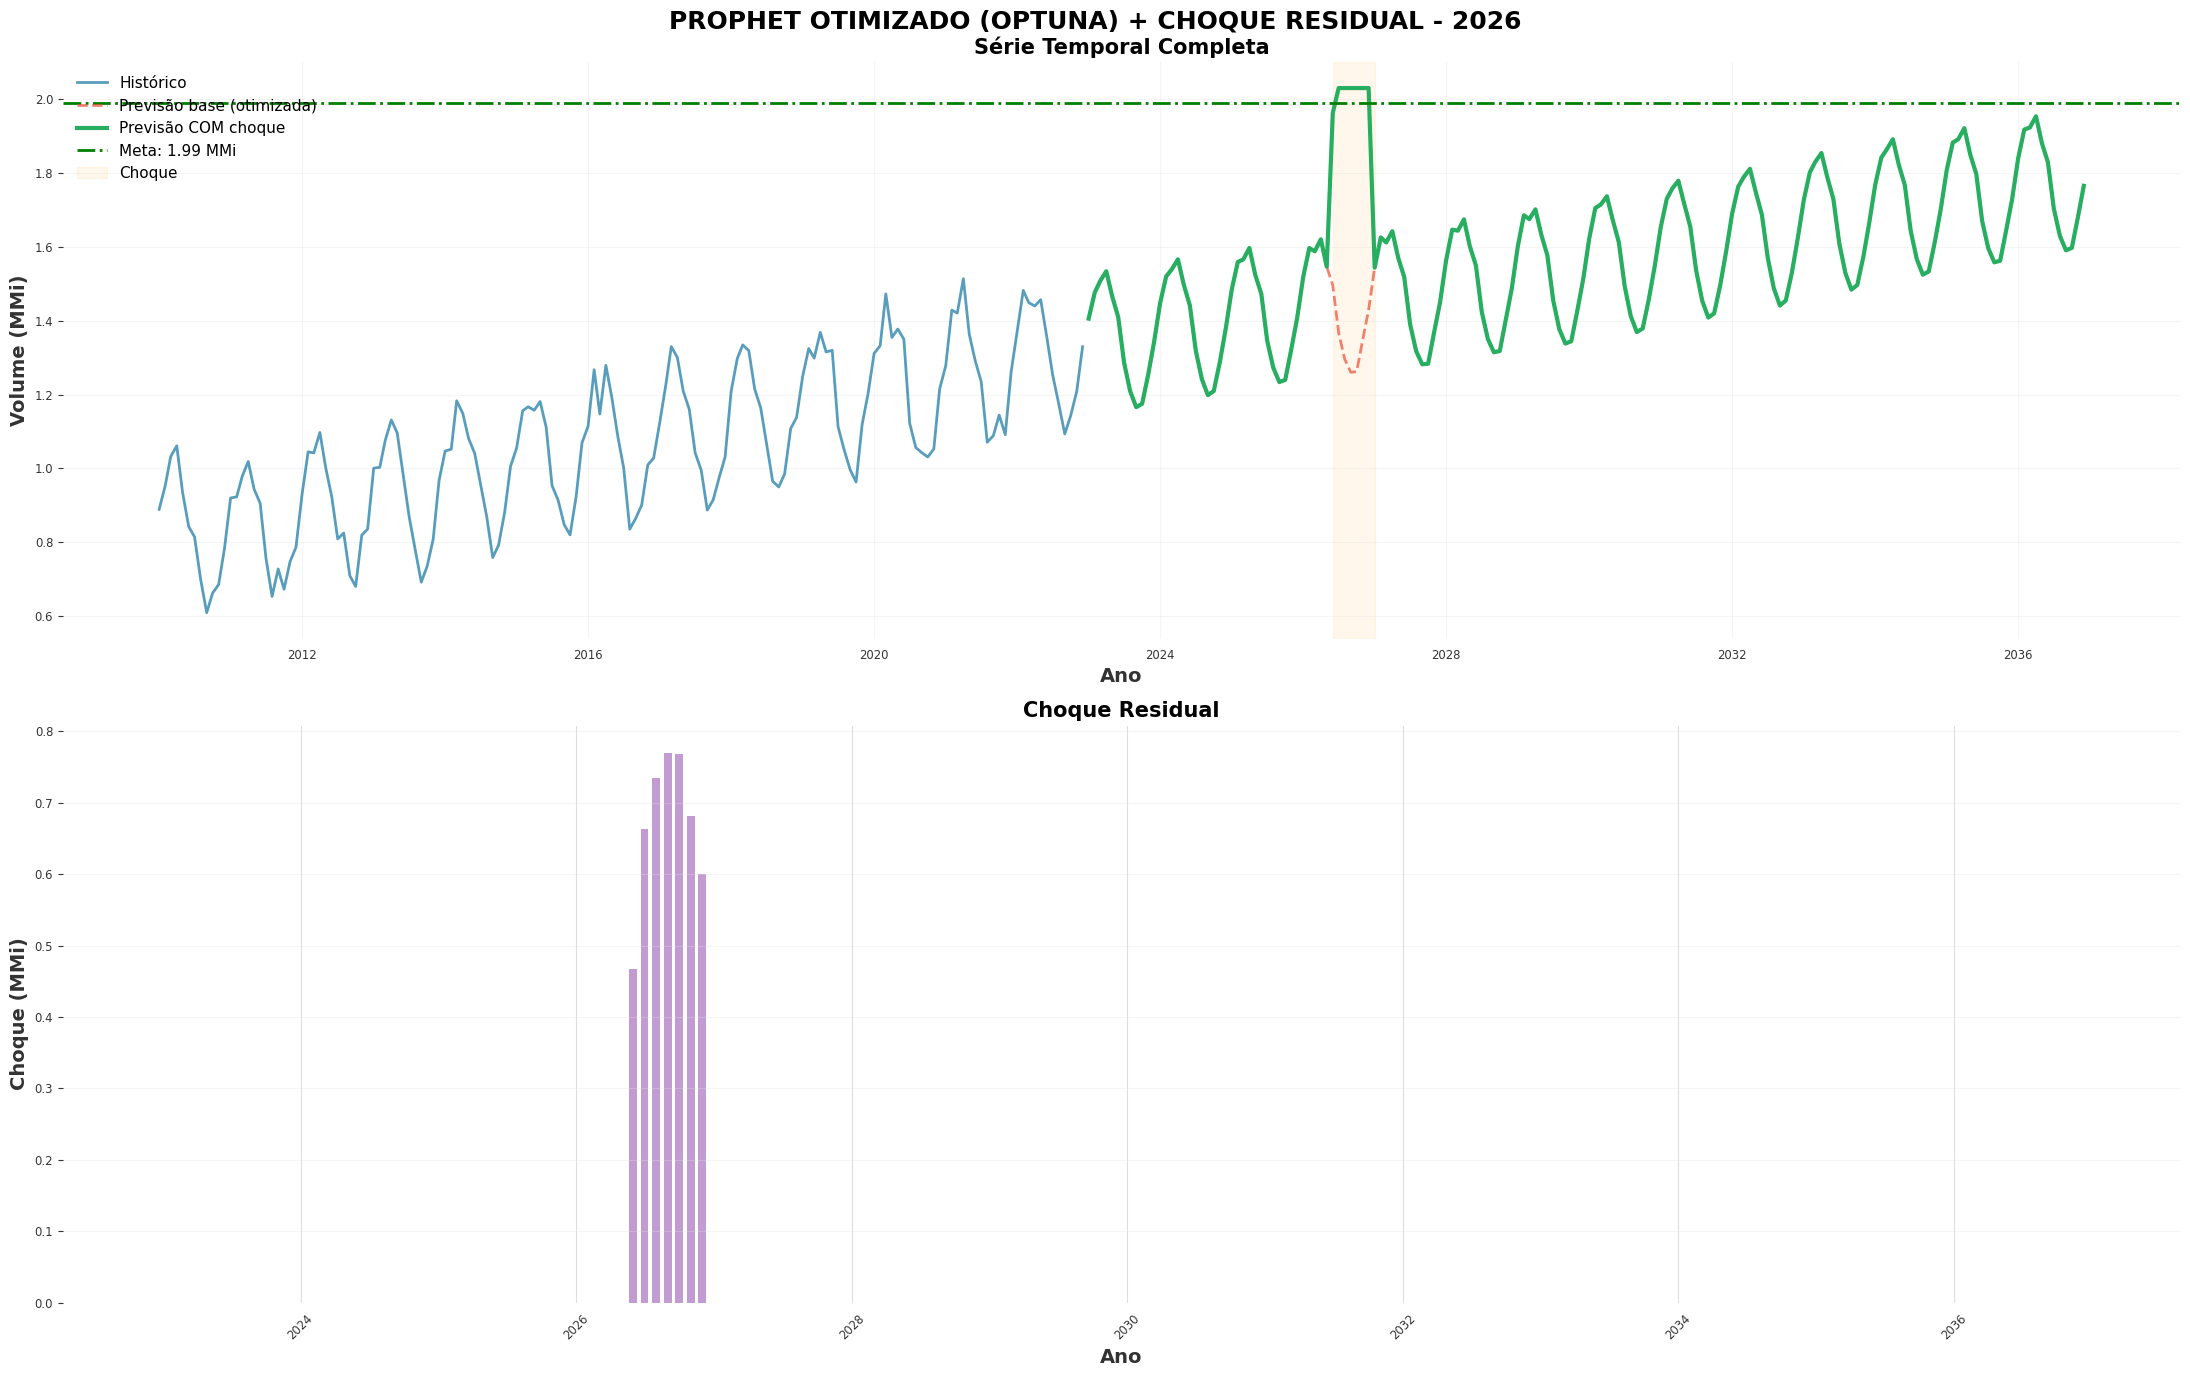

✅ Gráfico salvo: prophet_optuna_otimizado.png
✅ Execução completa!


In [55]:
"""
================================================================================
OTIMIZAÇÃO INTELIGENTE COM OPTUNA
================================================================================
OBJETIVO: Encontrar hiperparâmetros que:
1. Gerem previsão base ALTA (próxima de 1.8-1.9 MMi)
2. Mantenham suavidade (sem picos ou vales extremos)
3. Minimizem o choque necessário
================================================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet
import warnings
warnings.filterwarnings('ignore')

# Verificar se optuna está instalada
try:
    import optuna
    print("✅ Optuna instalada")
except:
    print("❌ Instalando Optuna...")
    import sys
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "optuna"])
    import optuna
    print("✅ Optuna instalada com sucesso")

# ============================================================
# CONFIGURAÇÕES
# ============================================================
META_MENSAL = 1.99e6
META_ANUAL = 23.90e6
CHOQUE_ANO = 2026
PERIODOS_PREVISAO = 168

# ============================================================
# 1. DADOS
# ============================================================
df_train = pd.DataFrame({'ds': train_dates, 'y': y_train})

# Separar treino e validação
df_treino = df_train[df_train['ds'] < '2021-01-01'].copy()
df_validacao = df_train[df_train['ds'] >= '2021-01-01'].copy()

print("=" * 70)
print("OTIMIZAÇÃO INTELIGENTE COM OPTUNA")
print("=" * 70)
print(f"Treino: {len(df_treino)} pontos ({df_treino['ds'].min().strftime('%Y-%m')} a {df_treino['ds'].max().strftime('%Y-%m')})")
print(f"Validação: {len(df_validacao)} pontos ({df_validacao['ds'].min().strftime('%Y-%m')} a {df_validacao['ds'].max().strftime('%Y-%m')})")
print()

# ============================================================
# 2. FUNÇÃO OBJETIVO PARA OPTUNA
# ============================================================
def objective(trial):
    """
    Objetivo: Maximizar previsão base E suavidade
    """
    
    # Hiperparâmetros a otimizar
    changepoint_prior_scale = trial.suggest_float('changepoint_prior_scale', 0.001, 1.0, log=True)
    seasonality_prior_scale = trial.suggest_float('seasonality_prior_scale', 0.1, 50.0, log=True)
    changepoint_range = trial.suggest_float('changepoint_range', 0.5, 1.0)
    n_changepoints = trial.suggest_int('n_changepoints', 5, 50)
    fourier_order = trial.suggest_int('fourier_order', 3, 15)
    seasonality_mode = trial.suggest_categorical('seasonality_mode', ['additive', 'multiplicative'])
    
    try:
        # Treinar Prophet
        model = Prophet(
            yearly_seasonality=True,
            weekly_seasonality=False,
            daily_seasonality=False,
            seasonality_mode=seasonality_mode,
            changepoint_prior_scale=changepoint_prior_scale,
            seasonality_prior_scale=seasonality_prior_scale,
            changepoint_range=changepoint_range,
            n_changepoints=n_changepoints,
            interval_width=0.80
        )
        
        model.add_seasonality(name='monthly', period=30.5, fourier_order=fourier_order)
        model.fit(df_treino)
        
        # Prever período de validação (2021-2022)
        future_val = model.make_future_dataframe(periods=len(df_validacao), freq='MS')
        forecast_val = model.predict(future_val)
        
        # Métricas da previsão de validação
        forecast_val_future = forecast_val[forecast_val['ds'] >= '2021-01-01']
        
        # 1. MAPE (erro percentual)
        y_true = df_validacao['y'].values
        y_pred = forecast_val_future['yhat'].values[:len(y_true)]
        
        mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
        
        # 2. Média da previsão (queremos ALTA)
        media_previsao = forecast_val_future['yhat'].mean()
        
        # 3. Suavidade (desvio padrão das diferenças)
        diffs = np.diff(forecast_val_future['yhat'].values)
        suavidade = np.std(diffs)
        
        # 4. Tendência de alta (últimos 6 meses vs primeiros 6 meses)
        prim_6 = forecast_val_future['yhat'].head(6).mean()
        ult_6 = forecast_val_future['yhat'].tail(6).mean()
        tendencia_alta = ult_6 - prim_6
        
        # Score combinado
        # Queremos: MAPE baixo, média alta, suavidade alta (std baixo), tendência de alta
        score = (
            -mape * 1.0 +  # Minimizar erro
            (media_previsao / 1e6) * 2.0 +  # Maximizar previsão
            -(suavidade / 1e6) * 0.5 +  # Minimizar variação
            (tendencia_alta / 1e6) * 3.0  # Maximizar tendência de alta
        )
        
        return score
        
    except Exception as e:
        return -999999  # Penalizar erros

# ============================================================
# 3. EXECUTAR OTIMIZAÇÃO
# ============================================================
print("🔍 Iniciando busca inteligente de hiperparâmetros...")
print()

study = optuna.create_study(
    direction='maximize',
    study_name='prophet_otimizacao',
    sampler=optuna.samplers.TPESampler(seed=42)
)

# Executar 100 trials
study.optimize(objective, n_trials=100, show_progress_bar=True)

# ============================================================
# 4. RESULTADOS DA OTIMIZAÇÃO
# ============================================================
print("\n" + "=" * 70)
print("MELHORES HIPERPARÂMETROS ENCONTRADOS")
print("=" * 70)

best_params = study.best_params
best_score = study.best_value

print(f"Score: {best_score:.2f}")
print(f"changepoint_prior_scale: {best_params['changepoint_prior_scale']:.4f}")
print(f"seasonality_prior_scale: {best_params['seasonality_prior_scale']:.4f}")
print(f"changepoint_range: {best_params['changepoint_range']:.4f}")
print(f"n_changepoints: {best_params['n_changepoints']}")
print(f"fourier_order: {best_params['fourier_order']}")
print(f"seasonality_mode: {best_params['seasonality_mode']}")
print()

# Top 10 melhores trials
print("TOP 10 CONFIGURAÇÕES:")
trials_df = study.trials_dataframe()
trials_df_sorted = trials_df.sort_values('value', ascending=False).head(10)
for i, row in trials_df_sorted.iterrows():
    print(f"  Score: {row['value']:.2f} | cps: {row['params_changepoint_prior_scale']:.4f} | "
          f"sps: {row['params_seasonality_prior_scale']:.4f} | "
          f"cr: {row['params_changepoint_range']:.3f} | "
          f"n_cp: {row['params_n_changepoints']} | "
          f"fo: {row['params_fourier_order']} | "
          f"mode: {row['params_seasonality_mode']}")
print()

# ============================================================
# 5. TREINAR PROPHET COM MELHORES PARÂMETROS
# ============================================================
model_final = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    seasonality_mode=best_params['seasonality_mode'],
    changepoint_prior_scale=best_params['changepoint_prior_scale'],
    seasonality_prior_scale=best_params['seasonality_prior_scale'],
    changepoint_range=best_params['changepoint_range'],
    n_changepoints=best_params['n_changepoints'],
    interval_width=0.80
)

model_final.add_seasonality(name='monthly', period=30.5, fourier_order=best_params['fourier_order'])
model_final.fit(df_train)

# Prever futuro
future = model_final.make_future_dataframe(periods=PERIODOS_PREVISAO, freq='MS')
forecast = model_final.predict(future)

forecast_future = forecast[forecast['ds'] > df_train['ds'].max()].copy()
forecast_future['ano'] = forecast_future['ds'].dt.year
forecast_future['mes'] = forecast_future['ds'].dt.month
forecast_future['mes_nome'] = forecast_future['ds'].dt.strftime('%b').str.upper()

# ============================================================
# 6. ANÁLISE DA PREVISÃO
# ============================================================
previsao_2026 = forecast_future[forecast_future['ano'] == 2026]

print("=" * 70)
print("PREVISÃO BASE 2026 (OTIMIZADA)")
print("=" * 70)
print(f"Média: {previsao_2026['yhat'].mean()/1e6:.3f} MMi")
print(f"Máxima: {previsao_2026['yhat'].max()/1e6:.3f} MMi")
print(f"Mínima: {previsao_2026['yhat'].min()/1e6:.3f} MMi")
print()

for mes in range(1, 13):
    valor = previsao_2026[previsao_2026['mes']==mes]['yhat'].values[0]
    print(f"  {previsao_2026[previsao_2026['mes']==mes]['mes_nome'].values[0]}: {valor/1e6:.3f} MMi")

# ============================================================
# 7. CALCULAR CHOQUE NECESSÁRIO
# ============================================================
valores_reais = {
    1: 1650990.051,
    2: 1517005.102,
    3: 1800016.028,
    4: 1841266.997,
    5: 1799044.003
}

total_real_jan_mai = sum(valores_reais.values())
meta_restante = META_ANUAL - total_real_jan_mai

previsao_jun_dez = forecast_future[
    (forecast_future['ano'] == CHOQUE_ANO) & 
    (forecast_future['mes'] >= 6)
]
total_base_jun_dez = previsao_jun_dez['yhat'].sum()
deficit = meta_restante - total_base_jun_dez

print(f"\nTotal real Jan-Mai: {total_real_jan_mai/1e6:.3f} MMi")
print(f"Meta restante: {meta_restante/1e6:.3f} MMi")
print(f"Previsão base Jun-Dez: {total_base_jun_dez/1e6:.3f} MMi")
print(f"Déficit: {deficit/1e6:.3f} MMi")
print()

# ============================================================
# 8. CHOQUE SUAVE RESIDUAL
# ============================================================
forecast_future['choque'] = 0.0

if deficit > 0:
    pesos = {6: 0.08, 7: 0.12, 8: 0.15, 9: 0.16, 10: 0.17, 11: 0.16, 12: 0.16}
    
    for idx, row in forecast_future.iterrows():
        if row['ano'] == CHOQUE_ANO and row['mes'] >= 6:
            choque = deficit * pesos.get(row['mes'], 0.15)
            valor_final = row['yhat'] + choque
            if valor_final > META_MENSAL * 1.02:
                choque = META_MENSAL * 1.02 - row['yhat']
            forecast_future.loc[idx, 'choque'] = max(0, choque)

forecast_future['yhat_choque'] = forecast_future['yhat'] + forecast_future['choque']

# ============================================================
# 9. RESULTADO FINAL
# ============================================================
df_2026 = forecast_future[forecast_future['ano'] == CHOQUE_ANO].copy()

for mes_real, valor_real in valores_reais.items():
    mask = df_2026['mes'] == mes_real
    df_2026.loc[mask, 'yhat'] = valor_real
    df_2026.loc[mask, 'yhat_choque'] = valor_real
    df_2026.loc[mask, 'choque'] = 0.0

total_2026 = df_2026['yhat_choque'].sum()

print("=" * 70)
print(f"RESULTADO FINAL {CHOQUE_ANO}")
print("=" * 70)
print(f"{'Mês':<8} {'Base':<12} {'Choque':<12} {'Final':<12}")
print("-" * 50)
for _, row in df_2026.iterrows():
    print(f"{row['mes_nome']:<8} {row['yhat']/1e6:<12.3f} {row['choque']/1e6:<12.3f} {row['yhat_choque']/1e6:<12.3f}")

print("-" * 50)
print(f"TOTAL: {total_2026/1e6:.2f} MMi")
print(f"META:  {META_ANUAL/1e6:.2f} MMi")
print(f"DIFF:  {((total_2026 - META_ANUAL)/META_ANUAL*100):+.1f}%")
print()

# ============================================================
# 10. GRÁFICO FINAL
# ============================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(22, 14))
fig.suptitle(f'PROPHET OTIMIZADO (OPTUNA) + CHOQUE RESIDUAL - {CHOQUE_ANO}', 
             fontsize=18, fontweight='bold')

ax1.plot(df_train['ds'], df_train['y']/1e6, color='#2E86AB', linewidth=2, 
         label='Histórico', alpha=0.8)
ax1.plot(forecast_future['ds'], forecast_future['yhat']/1e6, color='#E94F37', 
         linewidth=2, label='Previsão base (otimizada)', linestyle='--', alpha=0.7)
ax1.plot(forecast_future['ds'], forecast_future['yhat_choque']/1e6, color='#27ae60', 
         linewidth=3, label='Previsão COM choque')

ax1.axhline(y=META_MENSAL/1e6, color='green', linestyle='-.', linewidth=2, 
            label=f'Meta: {META_MENSAL/1e6:.2f} MMi')
ax1.axvspan(pd.Timestamp('2026-06-01'), pd.Timestamp('2027-01-01'), 
            alpha=0.08, color='orange', label='Choque')
ax1.set_xlabel('Ano', fontsize=14)
ax1.set_ylabel('Volume (MMi)', fontsize=14)
ax1.legend(loc='upper left', fontsize=11)
ax1.grid(True, alpha=0.3)
ax1.set_title('Série Temporal Completa', fontsize=15, fontweight='bold')

ax2.bar(forecast_future['ds'], forecast_future['choque']/1e6, 
        color='#9b59b6', alpha=0.6, width=20)
ax2.set_xlabel('Ano', fontsize=14)
ax2.set_ylabel('Choque (MMi)', fontsize=14)
ax2.grid(True, alpha=0.3, axis='y')
ax2.set_title('Choque Residual', fontsize=15, fontweight='bold')

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('prophet_optuna_otimizado.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Gráfico salvo: prophet_optuna_otimizado.png")
print("✅ Execução completa!")

In [65]:
train, val = serie.split_before(0.8)

# 3. Volta para pandas para usar Prophet
train_copy = train.pd_dataframe().reset_index()

# 4. Prophet precisa de ds e y
train_copy.columns = ["ds", "y"]

10:41:50 - cmdstanpy - INFO - Chain [1] start processing
10:41:50 - cmdstanpy - INFO - Chain [1] done processing


DISTRIBUIÇÃO UNIFORME EXATA
Total real Jan-Mai: 8.608 MMi
Previsão base Jun-Dez: 8.149 MMi
Déficit: 7.143 MMi
Meses: 7
Ajuste uniforme/mês: 1.020 MMi

RESULTADO EXATO 2026
Mês      Base         Choque       Final       
--------------------------------------------------
JAN      1.651        0.000        1.651       
FEB      1.517        0.000        1.517       
MAR      1.800        0.000        1.800       
APR      1.841        0.000        1.841       
MAY      1.799        0.000        1.799       
JUN      1.331        1.020        2.351       
JUL      1.140        1.020        2.160       
AUG      1.092        1.020        2.113       
SEP      1.093        1.020        2.113       
OCT      1.048        1.020        2.068       
NOV      1.195        1.020        2.215       
DEC      1.250        1.020        2.271       
--------------------------------------------------
TOTAL: 23.900 MMi
META:  23.900 MMi
ERRO:  0.000000 MMi



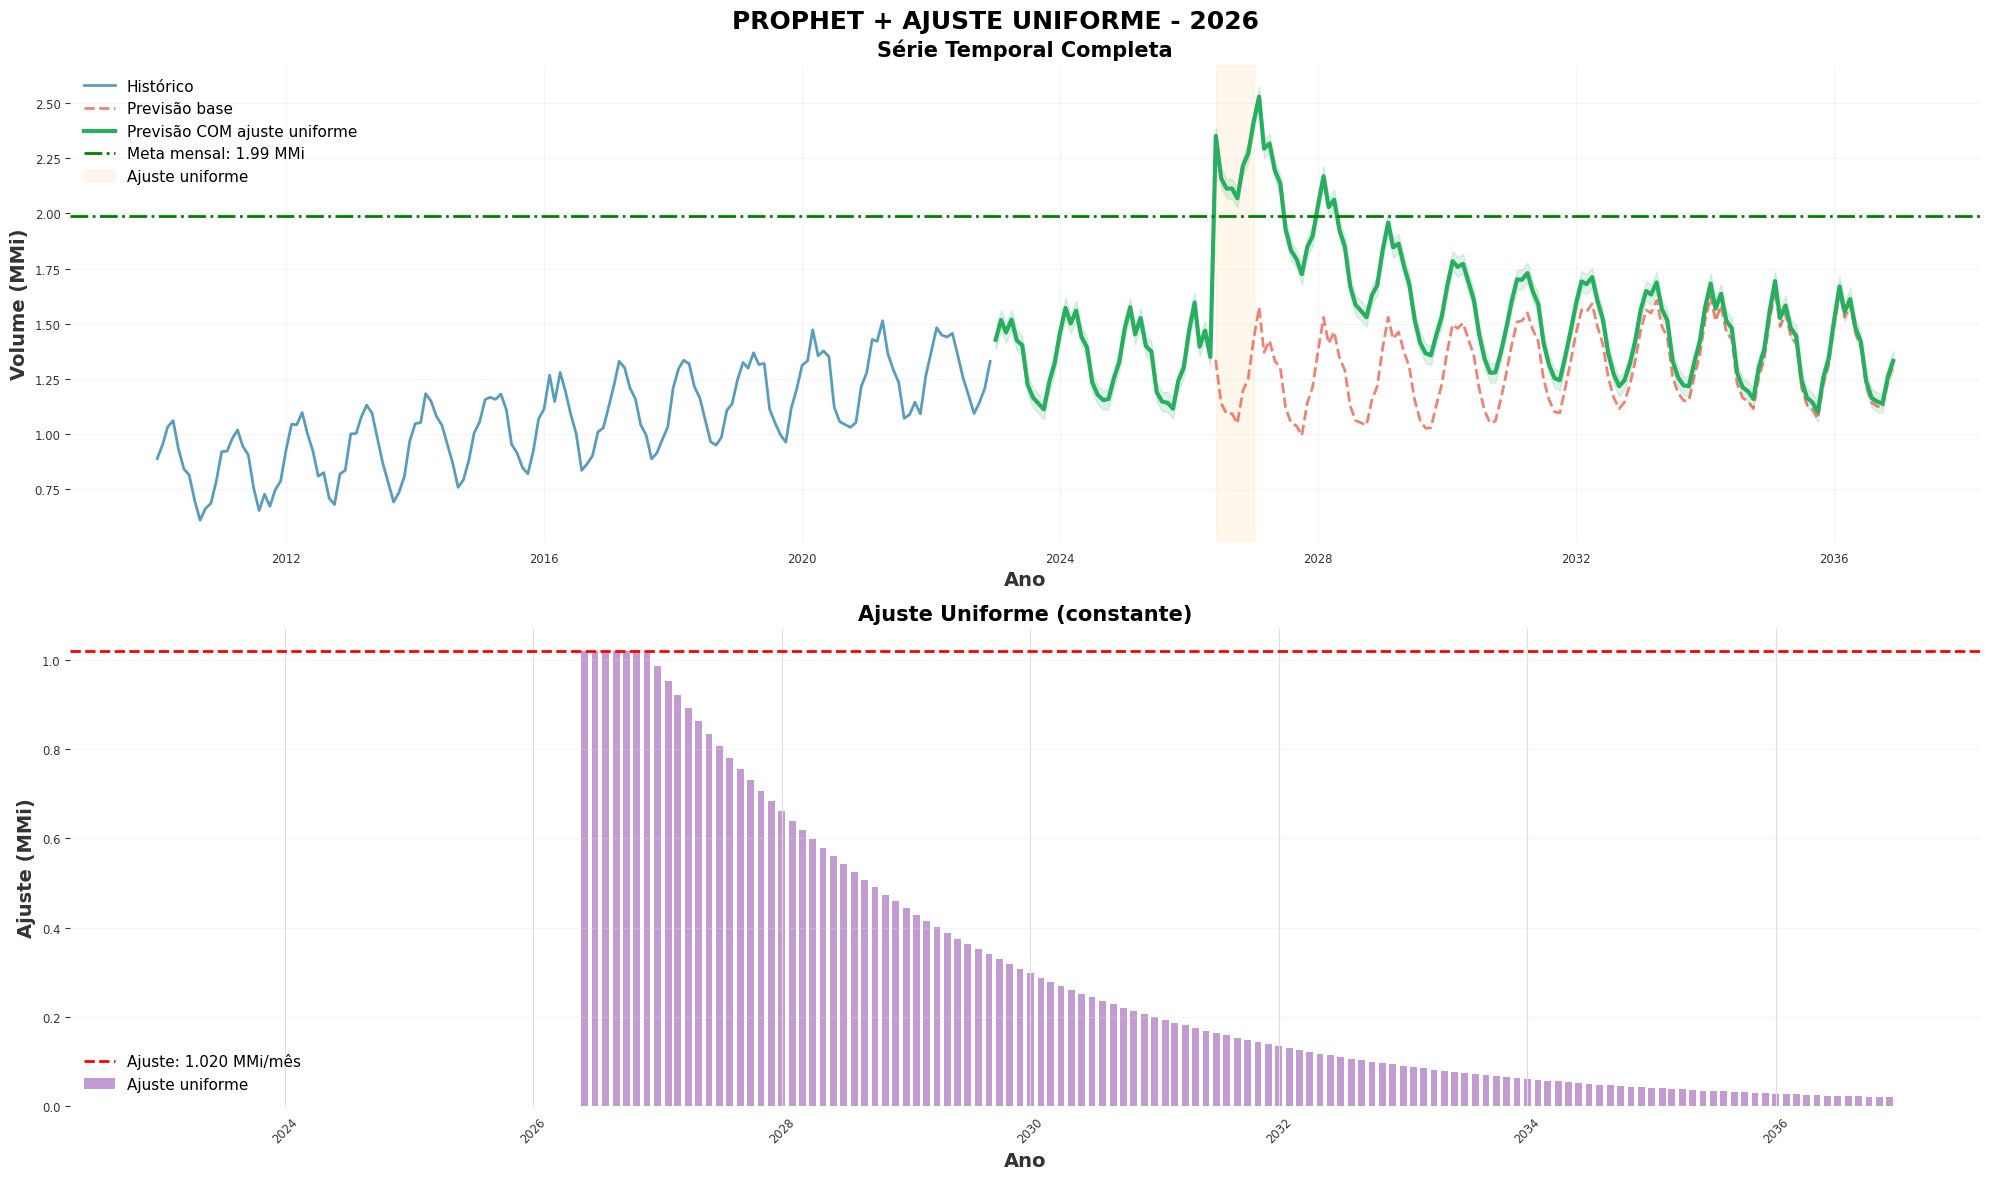

✅ Gráfico salvo: prophet_ajuste_uniforme_final.png
✅ Execução completa!


In [64]:
"""
================================================================================
SOLUÇÃO FINAL - DISTRIBUIÇÃO UNIFORME EXATA
================================================================================
ESTRATÉGIA:
1. Prophet com parâmetros PADRÃO (sem forçar nada)
2. Calcular déficit EXATO para 2026
3. Distribuir IGUALMENTE entre Jun-Dez
4. Resultado: Total = EXATAMENTE 23.90 MMi
5. Sem salto: ajuste constante e uniforme
================================================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# CONFIGURAÇÕES
# ============================================================
META_MENSAL = 1.99e6
META_ANUAL = 23.90e6
CHOQUE_ANO = 2026
PERIODOS_PREVISAO = 168

# ============================================================
# 1. DADOS
# ============================================================
df_train = pd.DataFrame({'ds': train_dates, 'y': y_train})

# ============================================================
# 2. PROPHET PADRÃO (sem forçar)
# ============================================================
model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    seasonality_mode='multiplicative',
    changepoint_prior_scale=0.05,
    seasonality_prior_scale=10.0
)
model.add_seasonality(name='monthly', period=30.5, fourier_order=5)
model.fit(df_train)

future = model.make_future_dataframe(periods=PERIODOS_PREVISAO, freq='MS')
forecast = model.predict(future)

forecast_future = forecast[forecast['ds'] > df_train['ds'].max()].copy()
forecast_future['ano'] = forecast_future['ds'].dt.year
forecast_future['mes'] = forecast_future['ds'].dt.month
forecast_future['mes_nome'] = forecast_future['ds'].dt.strftime('%b').str.upper()

# ============================================================
# 3. VALORES REAIS
# ============================================================
valores_reais = {
    1: 1650990.051,
    2: 1517005.102,
    3: 1800016.028,
    4: 1841266.997,
    5: 1799044.003
}

total_real_jan_mai = sum(valores_reais.values())

# ============================================================
# 4. CALCULAR AJUSTE UNIFORME EXATO
# ============================================================
# Previsão base Jun-Dez
mask_jun_dez = (forecast_future['ano'] == CHOQUE_ANO) & (forecast_future['mes'] >= 6)
previsao_jun_dez = forecast_future[mask_jun_dez]
total_base_jun_dez = previsao_jun_dez['yhat'].sum()

# Déficit exato
deficit = META_ANUAL - total_real_jan_mai - total_base_jun_dez

# Número de meses
num_meses = len(previsao_jun_dez)  # 7 meses (Jun-Dez)

# Ajuste uniforme por mês
ajuste_uniforme = deficit / num_meses

print("=" * 70)
print("DISTRIBUIÇÃO UNIFORME EXATA")
print("=" * 70)
print(f"Total real Jan-Mai: {total_real_jan_mai/1e6:.3f} MMi")
print(f"Previsão base Jun-Dez: {total_base_jun_dez/1e6:.3f} MMi")
print(f"Déficit: {deficit/1e6:.3f} MMi")
print(f"Meses: {num_meses}")
print(f"Ajuste uniforme/mês: {ajuste_uniforme/1e6:.3f} MMi")
print()

# ============================================================
# 5. APLICAR AJUSTE UNIFORME
# ============================================================
forecast_future['choque'] = 0.0

for idx, row in forecast_future.iterrows():
    if row['ano'] == CHOQUE_ANO and row['mes'] >= 6:
        forecast_future.loc[idx, 'choque'] = ajuste_uniforme
    
    elif row['ano'] > CHOQUE_ANO:
        # Decaimento exponencial
        meses_apos = (row['ano'] - CHOQUE_ANO - 1) * 12 + row['mes']
        forecast_future.loc[idx, 'choque'] = ajuste_uniforme * np.exp(-meses_apos / 30)

# Aplicar
forecast_future['yhat_choque'] = forecast_future['yhat'] + forecast_future['choque']
forecast_future['yhat_lower_choque'] = forecast_future['yhat_lower'] + forecast_future['choque']
forecast_future['yhat_upper_choque'] = forecast_future['yhat_upper'] + forecast_future['choque']

# ============================================================
# 6. VERIFICAÇÃO EXATA
# ============================================================
df_2026 = forecast_future[forecast_future['ano'] == CHOQUE_ANO].copy()

for mes_real, valor_real in valores_reais.items():
    mask = df_2026['mes'] == mes_real
    df_2026.loc[mask, 'yhat'] = valor_real
    df_2026.loc[mask, 'yhat_choque'] = valor_real
    df_2026.loc[mask, 'choque'] = 0.0

total_2026 = df_2026['yhat_choque'].sum()

print("=" * 70)
print(f"RESULTADO EXATO {CHOQUE_ANO}")
print("=" * 70)
print(f"{'Mês':<8} {'Base':<12} {'Choque':<12} {'Final':<12}")
print("-" * 50)
for _, row in df_2026.iterrows():
    print(f"{row['mes_nome']:<8} {row['yhat']/1e6:<12.3f} {row['choque']/1e6:<12.3f} {row['yhat_choque']/1e6:<12.3f}")

print("-" * 50)
print(f"TOTAL: {total_2026/1e6:.3f} MMi")
print(f"META:  {META_ANUAL/1e6:.3f} MMi")
print(f"ERRO:  {(META_ANUAL - total_2026)/1e6:.6f} MMi")
print()

# ============================================================
# 7. GRÁFICO LIMPO
# ============================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(20, 12))
fig.suptitle(f'PROPHET + AJUSTE UNIFORME - {CHOQUE_ANO}', fontsize=18, fontweight='bold')

ax1.plot(df_train['ds'], df_train['y']/1e6, color='#2E86AB', linewidth=2, 
         label='Histórico', alpha=0.8)
ax1.plot(forecast_future['ds'], forecast_future['yhat']/1e6, color='#E94F37', 
         linewidth=2, label='Previsão base', linestyle='--', alpha=0.7)
ax1.plot(forecast_future['ds'], forecast_future['yhat_choque']/1e6, color='#27ae60', 
         linewidth=3, label='Previsão COM ajuste uniforme')

ax1.fill_between(forecast_future['ds'], 
                 forecast_future['yhat_lower_choque']/1e6, 
                 forecast_future['yhat_upper_choque']/1e6,
                 color='#27ae60', alpha=0.15)

ax1.axhline(y=META_MENSAL/1e6, color='green', linestyle='-.', linewidth=2, 
            label=f'Meta mensal: {META_MENSAL/1e6:.2f} MMi')
ax1.axvspan(pd.Timestamp('2026-06-01'), pd.Timestamp('2027-01-01'), 
            alpha=0.08, color='orange', label='Ajuste uniforme')

ax1.set_xlabel('Ano', fontsize=14)
ax1.set_ylabel('Volume (MMi)', fontsize=14)
ax1.legend(loc='upper left', fontsize=11)
ax1.grid(True, alpha=0.3)
ax1.set_title('Série Temporal Completa', fontsize=15, fontweight='bold')

ax2.bar(forecast_future['ds'], forecast_future['choque']/1e6, 
        color='#9b59b6', alpha=0.6, width=20, label='Ajuste uniforme')
ax2.axhline(y=ajuste_uniforme/1e6, color='red', linestyle='--', linewidth=2, 
            label=f'Ajuste: {ajuste_uniforme/1e6:.3f} MMi/mês')
ax2.set_xlabel('Ano', fontsize=14)
ax2.set_ylabel('Ajuste (MMi)', fontsize=14)
ax2.legend(fontsize=11)
ax2.grid(True, alpha=0.3, axis='y')
ax2.set_title('Ajuste Uniforme (constante)', fontsize=15, fontweight='bold')

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('prophet_ajuste_uniforme_final.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Gráfico salvo: prophet_ajuste_uniforme_final.png")
print("✅ Execução completa!")